# Z24: detección temprana de daño, paso a paso

Este notebook sigue el orden en que se tomaron las decisiones. Cada paso muestra un análisis y la decisión que sale de él.

**Objetivo:** detectar el daño del puente lo antes posible a partir de sus frecuencias naturales, sin confundir con daño los cambios que produce la temperatura.

**Principio:** todo se desarrolla como si no se tuviera información del daño, porque en un puente real solo se conoce el comportamiento del puente sano. Los datos con daño se usan solo para evaluar, al final.

**Índice**
1. [Frecuencias frente a la temperatura](#sec1)
2. [Preparación del daño](#sec2)
3. [División de los datos y validación](#sec3)
4. [Primer modelo: solo la temperatura del momento](#sec4)
5. [Dos pendientes: una sobre 0 °C y otra bajo 0 °C](#sec5)
6. [¿Importa la temperatura de las horas anteriores?](#sec6)
7. [La historia de la temperatura en la regresión lineal](#sec7)
8. [Red neuronal](#sec8)
9. [Random forest](#sec9)
10. [Elección del modelo de cada modo](#sec10)
11. [Residuos en los bloques de prueba](#sec11)
12. [Un indicador con los tres residuos](#sec12)

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Fixed seed, so that any random result is always the same
SEED = 42
np.random.seed(SEED)

# Input files (in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering

MODES = [1, 2, 3]


# Shows a table with its caption above it
def show_table(table, number, caption, decimals=3):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals, na_rep="—"))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Frecuencias frente a la temperatura

**Datos:**
- Frecuencias de los modos 1, 2 y 3 ($f_1$, $f_2$, $f_3$), identificadas cada hora en `z24_natural_frequencies_ems.ipynb`.
- Temperatura del pavimento, $T$: promedio de los sensores TP1 y TP2 (TP3 no registró).
- Temperatura de la losa superior, $T_\text{losa}$: promedio de los sensores TDT2, TDT3, TDS1 y TDS2 (TDT1 no registró).
- Los códigos de error del registrador (valores de 100 °C o más) se dejan vacíos.

Solo se miran las mediciones del puente sano, antes del 05.08.1998.

In [2]:
# 1. Frequencies and temperatures (pavement TP, upper slab TDT and TDS)
PAVEMENT_SENSORS = ["TP1", "TP2"]
SLAB_SENSORS = ["TDT2", "TDT3", "TDS1", "TDS2"]
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code"] + PAVEMENT_SENSORS + SLAB_SENSORS)

# 2. Error codes of the data logger (for example 3276.7) are replaced by NaN
for column in PAVEMENT_SENSORS + SLAB_SENSORS:
    temperatures.loc[temperatures[column].abs() >= 100, column] = np.nan

# 3. Pavement temperature (T) and slab temperature (T_slab)
temperatures["T"] = temperatures[PAVEMENT_SENSORS].mean(axis=1)
temperatures["T_slab"] = temperatures[SLAB_SENSORS].mean(axis=1)

# 4. One table with both, in time order
data = pd.merge(frequencies, temperatures[["code", "T", "T_slab"]], on="code", how="left")
data = data.sort_values("start").reset_index(drop=True)

# 5. Healthy bridge: measurements before the damage preparation
healthy = data[data["start"] < PREP_START]

correlation = healthy["T"].corr(healthy["T_slab"])
print(f"Healthy measurements: {len(healthy)}, from {healthy['start'].min():%d.%m.%Y} to {healthy['start'].max():%d.%m.%Y}")
print(f"Correlation between pavement and slab temperature: {correlation:.3f}")
print(f"Pavement: from {healthy['T'].min():.1f} to {healthy['T'].max():.1f} °C")
print(f"Slab: from {healthy['T_slab'].min():.1f} to {healthy['T_slab'].max():.1f} °C")

Healthy measurements: 4821, from 10.11.1997 to 04.08.1998
Correlation between pavement and slab temperature: 0.982
Pavement: from -6.7 to 40.4 °C
Slab: from -5.4 to 32.0 °C


Las dos temperaturas están muy correlacionadas, pero la losa tiene un rango menor: el pavimento recibe el sol directo y se calienta más. Las figuras de este paso usan la del pavimento; en el paso 4 se comparan las dos como entrada del modelo.

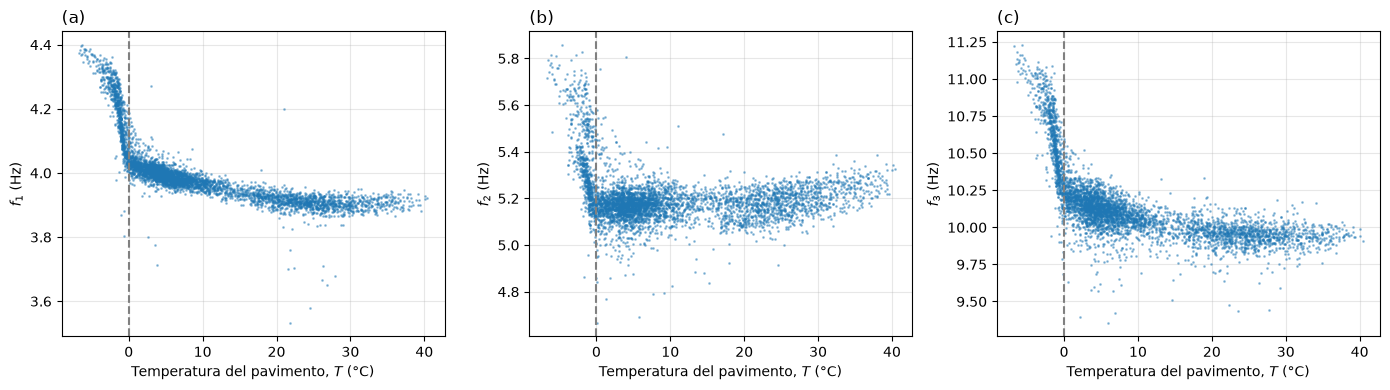

**Figura 1.** Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(healthy["T"], healthy["f1"], ".", markersize=2, alpha=0.4)
axes[1].plot(healthy["T"], healthy["f2"], ".", markersize=2, alpha=0.4)
axes[2].plot(healthy["T"], healthy["f3"], ".", markersize=2, alpha=0.4)

axes[0].set_ylabel("$f_1$ (Hz)")
axes[1].set_ylabel("$f_2$ (Hz)")
axes[2].set_ylabel("$f_3$ (Hz)")
axes[0].set_title("(a)", loc="left")
axes[1].set_title("(b)", loc="left")
axes[2].set_title("(c)", loc="left")
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")     # 0 °C
    ax.set_xlabel("Temperatura del pavimento, $T$ (°C)")
    ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): "
            "(a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

**Qué se ve:**

- **Sobre 0 °C:** las frecuencias bajan poco a poco al subir la temperatura ($f_1$, de unos 4.05 Hz a 0 °C a 3.90 Hz a 30 °C). $f_2$ casi no cambia.
- **Bajo 0 °C:** las tres suben con fuerza ($f_1$ hasta 4.4 Hz, $f_2$ hasta 5.8 Hz, $f_3$ hasta 11.2 Hz). El asfalto se congela y rigidiza el tablero.
- **Dispersión bajo 0 °C:** con la misma temperatura, la frecuencia cambia mucho (por ejemplo, $f_2$ entre 5.2 y 5.8 Hz a −2 °C). La temperatura del momento, sola, no explica esa dispersión.
- **Puntos aislados** lejos de la nube. Hipótesis: son errores de identificación de la frecuencia. Por ahora no se quita ninguno: en un monitoreo continuo tampoco se podrían revisar uno por uno.

**En resumen:** la relación no es lineal y tiene un quiebre en 0 °C.

---
<a id="sec2"></a>
## 2. Preparación del daño

Del 05.08.1998 al primer descenso de la pila (11.08.1998, 13:15) se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Son trabajos planificados, así que sus fechas se conocerían también en un puente real.

¿Cambiaron las frecuencias? Se marcan esas mediciones sobre la nube del puente sano (Figura 2) y en el tiempo (Figura 3).

Preparation measurements: 158


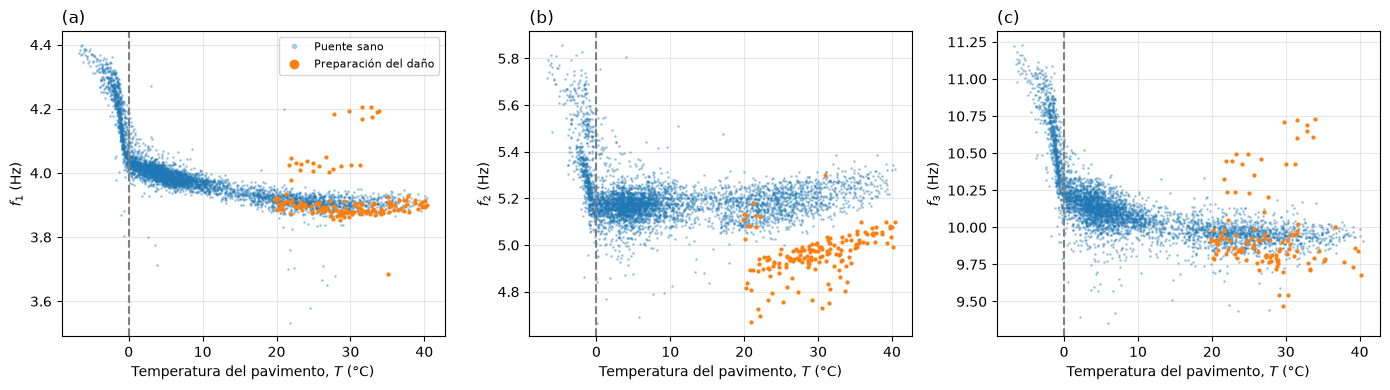

**Figura 2.** Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.

In [4]:
# Measurements of the damage preparation
preparation = data[(data["start"] >= PREP_START) & (data["start"] < DAMAGE_START)]
print(f"Preparation measurements: {len(preparation)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i in range(3):
    column = f"f{MODES[i]}"
    axes[i].plot(healthy["T"], healthy[column], ".", markersize=2, alpha=0.3, color="tab:blue", label="Puente sano")
    axes[i].plot(preparation["T"], preparation[column], ".", markersize=4, color="tab:orange",
                 label="Preparación del daño")
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"$f_{MODES[i]}$ (Hz)")
    axes[i].set_title(["(a)", "(b)", "(c)"][i], loc="left")
    axes[i].grid(alpha=0.3)
axes[0].legend(markerscale=3, fontsize=8)

fig.tight_layout()
show_figure(fig, 2, "Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del "
            "puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.")

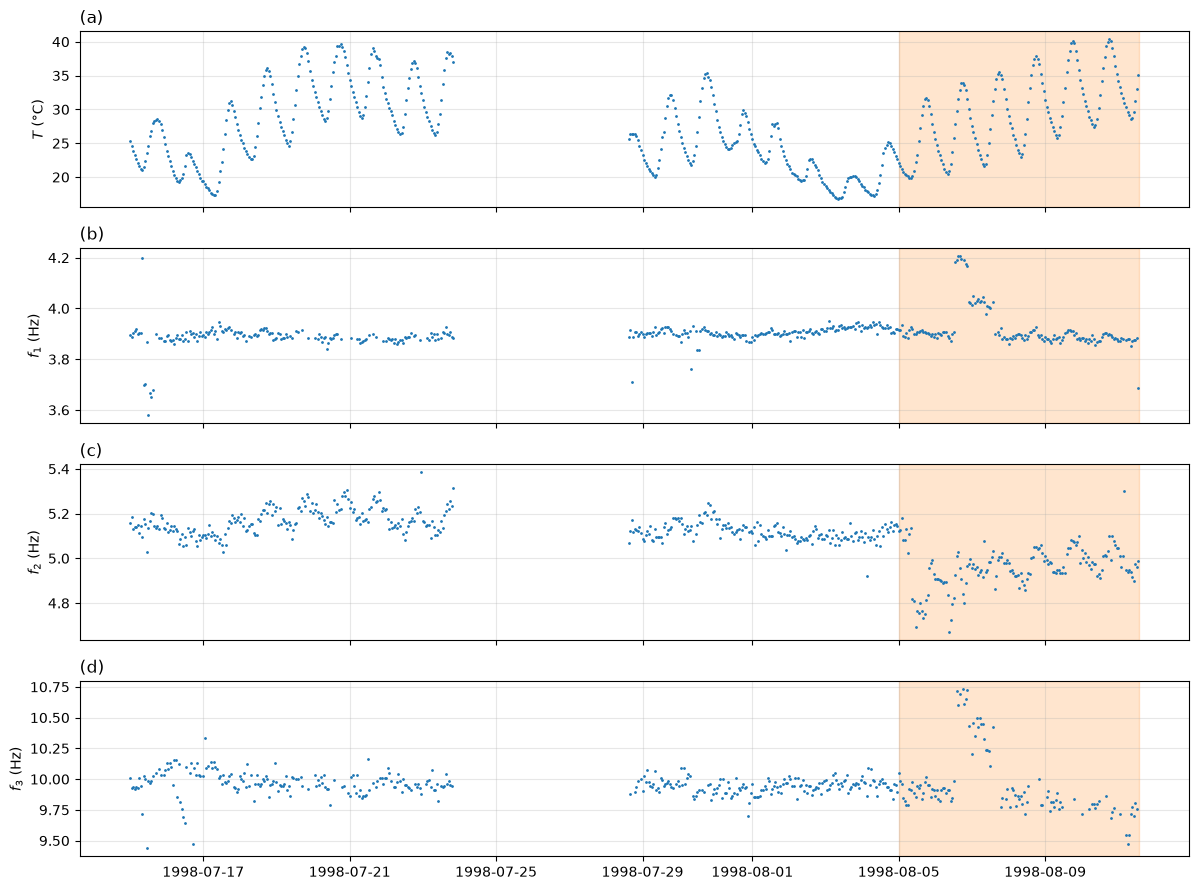

**Figura 3.** Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ y (d) $f_3$. La franja naranja es la preparación del daño.

In [5]:
# Three weeks before the preparation and the preparation itself
window = data[(data["start"] >= pd.Timestamp("1998-07-15")) & (data["start"] < DAMAGE_START)]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(window["start"], window["T"], ".", markersize=2)
axes[1].plot(window["start"], window["f1"], ".", markersize=2)
axes[2].plot(window["start"], window["f2"], ".", markersize=2)
axes[3].plot(window["start"], window["f3"], ".", markersize=2)

axes[0].set_ylabel("$T$ (°C)")
axes[1].set_ylabel("$f_1$ (Hz)")
axes[2].set_ylabel("$f_2$ (Hz)")
axes[3].set_ylabel("$f_3$ (Hz)")
labels = ["(a)", "(b)", "(c)", "(d)"]
for i in range(4):
    axes[i].axvspan(PREP_START, DAMAGE_START, color="tab:orange", alpha=0.2)    # preparation
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 3, "Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ "
            "y (d) $f_3$. La franja naranja es la preparación del daño.")

Para medirlo, se comparan las frecuencias con temperaturas parecidas: las mediciones entre 20 y 35 °C del puente sano y de la preparación.

In [6]:
# Median frequency of the healthy bridge and of the preparation, both between 20 and 35 °C
healthy_warm = healthy[(healthy["T"] >= 20) & (healthy["T"] <= 35)]
preparation_warm = preparation[(preparation["T"] >= 20) & (preparation["T"] <= 35)]

rows = []
for mode in MODES:
    column = f"f{mode}"
    healthy_median = healthy_warm[column].median()
    preparation_median = preparation_warm[column].median()
    rows.append({
        "Modo": mode,
        "Puente sano (Hz)": healthy_median,
        "Preparación (Hz)": preparation_median,
        "Cambio (%)": 100 * (preparation_median - healthy_median) / healthy_median,
    })
print(f"Measurements between 20 and 35 °C: healthy {len(healthy_warm)}, preparation {len(preparation_warm)}")
show_table(pd.DataFrame(rows), 1, "Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente "
           "sano y preparación del daño.")

Measurements between 20 and 35 °C: healthy 957, preparation 126


**Tabla 1.** Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente sano y preparación del daño.

Modo,Puente sano (Hz),Preparación (Hz),Cambio (%)
1,3.907,3.892,-0.373
2,5.192,4.946,-4.734
3,9.948,9.886,-0.621


**Qué se ve:**

- **$f_2$** baja el mismo 05.08 y se queda debajo de la nube del puente sano durante toda la preparación: −4.7 % a la misma temperatura (Tabla 1, Figura 3c).
- **$f_1$ y $f_3$** suben durante cerca de un día (06–07.08, hasta 4.2 y 10.7 Hz) y después vuelven cerca de sus valores sanos (Figura 3b y 3d).
- Un aumento de masa solo bajaría las frecuencias. Que unas suban y otras bajen indica que cambiaron las **condiciones de apoyo de la pila** mientras se cortaba y se ponían los gatos.

**Decisión:** las 158 mediciones de la preparación no representan al puente sano ni al daño que se busca. Se **excluyen del entrenamiento, de la validación y de la prueba**.

---
<a id="sec3"></a>
## 3. División de los datos y validación

### 3.1 Bloques de entrenamiento y de prueba

El método se tiene que probar en dos situaciones: con el puente sano, donde no debe indicar daño, y con el puente dañado, donde debe indicarlo lo antes posible. Se reservan tres bloques de prueba:

- **Puente sano, verano:** las 3 semanas anteriores a la preparación (15.07 al 04.08.1998). El daño empieza el 11.08.1998, en verano, así que este bloque prueba el puente sano en las mismas condiciones.
- **Puente sano, invierno:** dos semanas con helada, para probar el puente sano también bajo 0 °C. Las semanas se eligen abajo.
- **Puente dañado:** desde el primer descenso de la pila (11.08.1998).

El resto, hasta el 14.07.1998, es el **entrenamiento**.

Se quitan también las mediciones sin alguna frecuencia o sin temperatura: sin frecuencia no hay nada que comparar, y sin temperatura no se puede predecir.

**¿Qué dos semanas de invierno?** Hay pocas mediciones bajo 0 °C, y cada una que se va a la prueba se le quita al entrenamiento. Se comparan tres pares de semanas con helada moderada seguida de deshielo. Ninguno incluye la helada más fría, para que la prueba quede dentro del rango de temperatura del entrenamiento.

In [7]:
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block in summer

# 1. Complete measurements: the three frequencies and the two temperatures
complete = (data["f1"].notna() & data["f2"].notna() & data["f3"].notna()
            & data["T"].notna() & data["T_slab"].notna())

# 2. Complete measurements before the summer test
before_summer = data[complete & (data["start"] < TEST_START)]

# 3. Candidate two-week periods: name, first day, day after the last day
CANDIDATES = [
    ("01.12 al 14.12.1997", "1997-12-01", "1997-12-15"),
    ("15.12 al 28.12.1997", "1997-12-15", "1997-12-29"),
    ("12.01 al 25.01.1998", "1998-01-12", "1998-01-26"),
]

# 4. Frost in the test and frost left for training, for each candidate
rows = []
for name, first_day, end_day in CANDIDATES:
    in_test = (before_summer["start"] >= pd.Timestamp(first_day)) & (before_summer["start"] < pd.Timestamp(end_day))
    test = before_summer[in_test]
    rest = before_summer[~in_test]
    rows.append({
        "Semanas": name,
        "Mediciones válidas": len(test),
        "Bajo 0 °C en la prueba": (test["T"] < 0).sum(),
        "T mínima (°C)": test["T"].min(),
        "T máxima (°C)": test["T"].max(),
        "Bajo 0 °C en el entrenamiento": (rest["T"] < 0).sum(),
    })
show_table(pd.DataFrame(rows), 2, "Pares de semanas candidatos para la prueba de invierno: mediciones válidas, "
           "mediciones bajo 0 °C, rango de temperatura del pavimento y mediciones bajo 0 °C que quedarían en el "
           "entrenamiento.", decimals=1)

**Tabla 2.** Pares de semanas candidatos para la prueba de invierno: mediciones válidas, mediciones bajo 0 °C, rango de temperatura del pavimento y mediciones bajo 0 °C que quedarían en el entrenamiento.

Semanas,Mediciones válidas,Bajo 0 °C en la prueba,T mínima (°C),T máxima (°C),Bajo 0 °C en el entrenamiento
01.12 al 14.12.1997,321,152,-3.9,6.5,573
15.12 al 28.12.1997,320,82,-3.0,7.7,643
12.01 al 25.01.1998,304,144,-2.3,6.0,581


- Los tres pares tienen helada, entre −3.9 y 7.7 °C, dentro del rango del entrenamiento.
- Con el 01.12 o el 12.01, la prueba tendría más helada (152 y 144 mediciones bajo 0 °C), pero al entrenamiento le quedarían 573 y 581.
- Con el 15.12, la prueba tiene menos helada (82 mediciones, más el deshielo que le sigue) y al entrenamiento le quedan 643.

**Decisión:** la prueba de invierno va del **15.12 al 28.12.1997**. Deja más helada para ajustar los modelos y aun así prueba el puente sano bajo 0 °C.

In [8]:
WINTER_TEST_START = pd.Timestamp("1997-12-15")    # healthy test block in winter (two weeks)
WINTER_TEST_END = pd.Timestamp("1997-12-29")      # day after the last day


# 1. Time block of each measurement
def get_block(date):
    if date >= WINTER_TEST_START and date < WINTER_TEST_END:
        return "Prueba, puente sano (invierno)"
    elif date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano (verano)"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 2. Valid measurements: complete and not in the preparation
data["valid"] = complete & (data["block"] != "Preparación del daño")

# 3. Table of the blocks
BLOCK_USE = {
    "Entrenamiento": "Ajustar y comparar los modelos",
    "Prueba, puente sano (invierno)": "Solo evaluación: no debe indicar daño",
    "Prueba, puente sano (verano)": "Solo evaluación: no debe indicar daño",
    "Preparación del daño": "Excluida (paso 2)",
    "Prueba, con daño": "Solo evaluación: cuánto tarda en detectar",
}
rows = []
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    valid_data = block_data[block_data["valid"]]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y"),
        "Mediciones": len(block_data),
        "Válidas": len(valid_data),
        "T mínima (°C)": valid_data["T"].min(),
        "T máxima (°C)": valid_data["T"].max(),
        "Uso": BLOCK_USE[block],
    })
show_table(pd.DataFrame(rows), 3, "Bloques de tiempo: fechas, mediciones, mediciones válidas, rango de temperatura "
           "del pavimento de las mediciones válidas y uso.", decimals=1)

**Tabla 3.** Bloques de tiempo: fechas, mediciones, mediciones válidas, rango de temperatura del pavimento de las mediciones válidas y uso.

Bloque,Desde,Hasta,Mediciones,Válidas,T mínima (°C),T máxima (°C),Uso
Entrenamiento,10.11.1997,14.07.1998,4097,3933,-6.7,40.4,Ajustar y comparar los modelos
"Prueba, puente sano (invierno)",15.12.1997,28.12.1997,334,320,-3.0,7.7,Solo evaluación: no debe indicar daño
"Prueba, puente sano (verano)",15.07.1998,04.08.1998,390,324,16.8,39.1,Solo evaluación: no debe indicar daño
Preparación del daño,05.08.1998,11.08.1998,158,0,—,—,Excluida (paso 2)
"Prueba, con daño",11.08.1998,10.09.1998,674,494,14.0,39.5,Solo evaluación: cuánto tarda en detectar


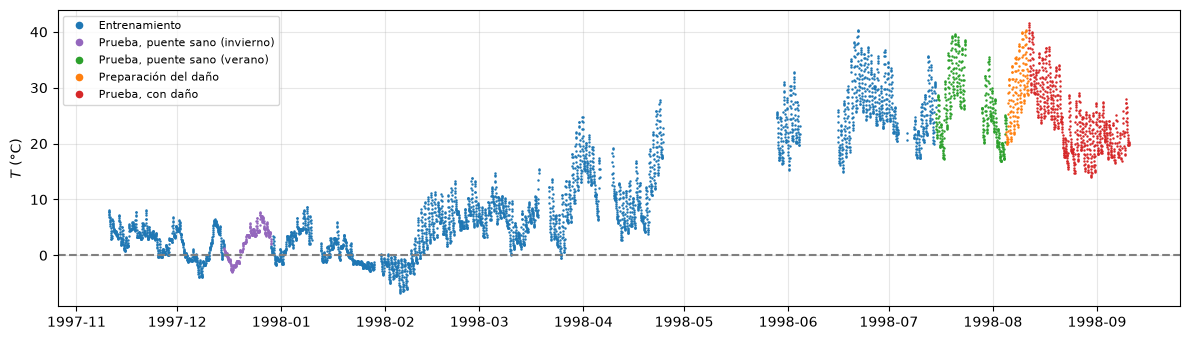

**Figura 4.** Temperatura del pavimento del 10.11.1997 al 10.09.1998, por bloque. La línea discontinua marca 0 °C.

In [9]:
COLORS = {"Entrenamiento": "tab:blue", "Prueba, puente sano (invierno)": "tab:purple",
          "Prueba, puente sano (verano)": "tab:green",
          "Preparación del daño": "tab:orange", "Prueba, con daño": "tab:red"}

fig, ax = plt.subplots(figsize=(12, 3.5))
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    ax.plot(block_data["start"], block_data["T"], ".", markersize=1.5, color=COLORS[block], label=block)
ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("$T$ (°C)")
ax.legend(markerscale=6, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 4, "Temperatura del pavimento del 10.11.1997 al 10.09.1998, por bloque. La línea discontinua marca "
            "0 °C.")

**Qué se ve:**

- El entrenamiento va de noviembre a mediados de julio, con un vacío sin datos en mayo, y cubre de −6.7 a 40.4 °C (Figura 4).
- La prueba de invierno va de −3.0 a 7.7 °C y las de verano de 14.0 a 39.5 °C, todas dentro del rango del entrenamiento (Tabla 3).
- Con la losa, el entrenamiento llega a 30.6 °C. Solo 4 mediciones de prueba lo superan, por menos de 1.2 °C (1 del verano sano y 3 con daño).
- **Limitaciones:** la prueba de invierno solo tiene helada moderada, y el daño solo se puede probar en verano.

### 3.2 ¿Por qué no un k-fold aleatorio?

Para comparar modelos sin tocar la prueba se usa **validación cruzada de $k$ folds**: el entrenamiento se divide en $k$ partes (folds); cada fold se predice con un modelo ajustado con los otros $k-1$, y el error se mide en las predicciones de todos los folds.

En un k-fold aleatorio, cada medición queda en un fold al azar. El problema es que las mediciones son cada hora y una hora se parece mucho a la anterior. Se comprueba prediciendo cada frecuencia con el valor de la hora anterior, sin ningún modelo:

In [10]:
training = data[(data["block"] == "Entrenamiento") & data["valid"]].copy()

# Hours between each measurement and the previous one
hours_since_previous = training["start"].diff().dt.total_seconds() / 3600
consecutive = hours_since_previous <= 1.5

rows = []
for mode in MODES:
    column = f"f{mode}"
    change = training[column].diff()[consecutive]          # frequency minus the one of the previous hour
    rows.append({
        "Modo": mode,
        "Desviación estándar de la frecuencia (Hz)": training[column].std(),
        "Error al copiar la hora anterior (Hz)": np.sqrt(np.mean(change ** 2)),
    })
show_table(pd.DataFrame(rows), 4, "Variación de cada frecuencia en el entrenamiento y error (raíz del error "
           "cuadrático medio) al predecirla con la medición de la hora anterior.")

**Tabla 4.** Variación de cada frecuencia en el entrenamiento y error (raíz del error cuadrático medio) al predecirla con la medición de la hora anterior.

Modo,Desviación estándar de la frecuencia (Hz),Error al copiar la hora anterior (Hz)
1,0.099,0.025
2,0.119,0.069
3,0.248,0.126


- Copiar la hora anterior ya da un error de 0.025 Hz en $f_1$, la cuarta parte de su variación (0.099 Hz).
- En un k-fold aleatorio, casi toda medición de validación tiene a su vecina en el entrenamiento. El error medido sería el de copiar a la vecina, no el de predecir días que el modelo no ha visto. Sería **optimista**.

**Decisión:** los folds se forman con **bloques de tiempo**, no con mediciones sueltas.

### 3.3 Tamaño del bloque

El bloque tiene que ser más largo que los episodios de helada, para no partirlos entre entrenamiento y validación, pero lo bastante corto para que todos los folds tengan helada.

In [11]:
# 1. Frost episodes: consecutive measurements with T below 0 °C (all training measurements, in time order)
training_all = data[data["block"] == "Entrenamiento"]
episode_hours = []
episode_start = None
previous_start = None
for _, row in training_all.iterrows():
    if row["T"] < 0:
        if episode_start is None:
            episode_start = row["start"]
        previous_start = row["start"]
    elif episode_start is not None:
        episode_hours.append((previous_start - episode_start).total_seconds() / 3600)
        episode_start = None
episode_hours = np.array(episode_hours)

print(f"Frost episodes in training: {len(episode_hours)}")
print(f"Longer than 1 day: {(episode_hours > 24).sum()}, longest: {episode_hours.max() / 24:.1f} days")

Frost episodes in training: 23
Longer than 1 day: 7, longest: 8.6 days


Con bloques de un día, 7 episodios quedarían partidos. Las dos opciones razonables son semanas o meses, repartidos por turnos en $k = 5$ folds (bloque 0 → fold 1, bloque 1 → fold 2, ..., bloque 5 → fold 1). Se compara cuántas mediciones bajo 0 °C recibe cada fold:

In [12]:
N_FOLDS = 5
first_date = training["start"].min().normalize()      # midnight of the first day (Monday 10.11.1997)

# 1. Weekly blocks: week counted from the first measurement
week = (training["start"] - first_date).dt.days // 7
training["fold"] = week % N_FOLDS + 1

# 2. Monthly blocks, for comparison: month counted from the first month
month = (training["start"].dt.year - first_date.year) * 12 + training["start"].dt.month - first_date.month
monthly_fold = month % N_FOLDS + 1

# 3. Measurements below 0 °C in each fold
below_zero = training["T"] < 0
rows = []
for fold in range(1, N_FOLDS + 1):
    rows.append({
        "Fold": fold,
        "Mediciones (semanas)": (training["fold"] == fold).sum(),
        "Bajo 0 °C (semanas)": ((training["fold"] == fold) & below_zero).sum(),
        "Mediciones (meses)": (monthly_fold == fold).sum(),
        "Bajo 0 °C (meses)": ((monthly_fold == fold) & below_zero).sum(),
    })
print(f"Weeks in training: {week.max() + 1}, months: {month.max() + 1}")
show_table(pd.DataFrame(rows), 5, "Mediciones válidas y mediciones bajo 0 °C de cada fold, con bloques de una "
           "semana y de un mes repartidos por turnos.")

Weeks in training: 36, months: 9


**Tabla 5.** Mediciones válidas y mediciones bajo 0 °C de cada fold, con bloques de una semana y de un mes repartidos por turnos.

Fold,Mediciones (semanas),Bajo 0 °C (semanas),Mediciones (meses),Bajo 0 °C (meses)
1,677,101,932,17
2,650,109,471,190
3,955,207,1036,245
4,833,120,846,187
5,818,106,648,4


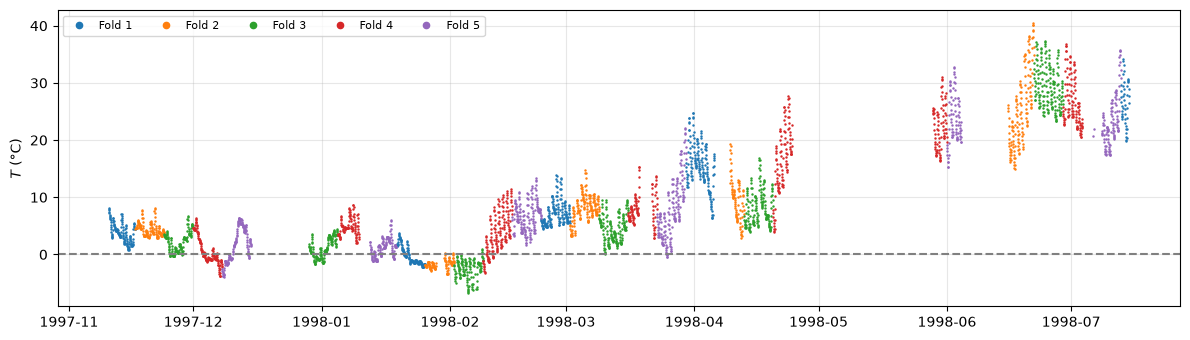

**Figura 5.** Temperatura del pavimento en el entrenamiento, coloreada por fold (bloques de una semana repartidos por turnos). La línea discontinua marca 0 °C.

In [13]:
FOLD_COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

fig, ax = plt.subplots(figsize=(12, 3.5))
for fold in range(1, N_FOLDS + 1):
    fold_data = training[training["fold"] == fold]
    ax.plot(fold_data["start"], fold_data["T"], ".", markersize=1.5, color=FOLD_COLORS[fold - 1], label=f"Fold {fold}")
ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("$T$ (°C)")
ax.legend(markerscale=6, fontsize=8, ncol=5, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 5, "Temperatura del pavimento en el entrenamiento, coloreada por fold (bloques de una semana "
            "repartidos por turnos). La línea discontinua marca 0 °C.")

- **Con meses** (Tabla 5), la helada cae casi entera en los folds 2, 3 y 4. Los folds 1 y 5 casi no tienen mediciones bajo 0 °C, así que no medirían el error en invierno.
- **Con semanas**, todos los folds tienen entre 101 y 207 mediciones bajo 0 °C y entre 650 y 955 en total. Cada fold mezcla semanas de invierno y de verano (Figura 5).
- **Limitación:** el episodio más largo (8.6 días) y los que cruzan un cambio de semana sí quedan partidos.

**Decisión:** validación cruzada con **bloques de una semana repartidos por turnos en 5 folds**.

### 3.4 Métrica

Para cada modo $m$ y cada medición $i$, el **residuo** es la diferencia entre la frecuencia medida y la que predice el modelo:

$$
r_{m,i} = f_{m,i} - \hat{f}_{m,i}
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida y $\hat{f}_{m,i}$ la predicha por un modelo ajustado sin el fold de la medición $i$.

El error del modelo es la **raíz del error cuadrático medio** (RMSE), en Hz:

$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} r_{m,i}^2}
\tag{2}
$$

donde $n$ es el número de mediciones.

- Se calcula **por modo**, porque cada frecuencia tiene su propia escala (Tabla 4).
- Se calcula en total, **bajo 0 °C y sobre 0 °C**: la mayor dispersión está bajo 0 °C (Figura 1), pero esas mediciones son solo el 16 % del entrenamiento, así que el RMSE total escondería los errores de invierno.

---
<a id="sec4"></a>
## 4. Primer modelo: solo la temperatura del momento

Se empieza por lo más simple, con la validación cruzada del paso 3:

- **Referencia (media):** predice siempre la media de la frecuencia en los folds de ajuste. Cualquier modelo útil tiene que mejorarla.
- **Regresión lineal** con una sola variable, la temperatura del momento:

$$
\hat{f}_m = \beta_0 + \beta_1 \, T
\tag{3}
$$

donde $\hat{f}_m$ es la frecuencia predicha del modo $m$, $T$ la temperatura y $\beta_0$, $\beta_1$ los coeficientes que ajusta el modelo (la frecuencia a 0 °C y su cambio por cada °C).

La regresión se ajusta dos veces: con la temperatura del pavimento y con la de la losa. En las dos, "bajo 0 °C" se refiere al pavimento, para comparar las mismas mediciones.

In [14]:
# 1. Week-blocked cross-validation (step 3): out-of-fold prediction of every training measurement
def cross_validate(model_name, features, mode):
    column = f"f{mode}"
    predictions = np.zeros(len(training))
    for fold in range(1, N_FOLDS + 1):
        is_validation = (training["fold"] == fold).to_numpy()
        fit_part = training[~is_validation]
        validation_part = training[is_validation]

        if model_name == "Media":
            predictions[is_validation] = fit_part[column].mean()
        else:
            model = LinearRegression()
            model.fit(fit_part[features], fit_part[column])
            predictions[is_validation] = model.predict(validation_part[features])
    return predictions


# 2. RMSE (Eq. 2)
def rmse(residuals):
    return np.sqrt(np.mean(residuals ** 2))


# 3. Residuals (Eq. 1) and RMSE of the three models in each mode
#    (label in the table, model, input variables, short name for the columns)
MODELS = [("Media", "Media", ["T"], "mean"),
          ("Lineal, T del pavimento", "Lineal", ["T"], "pavement"),
          ("Lineal, T de la losa", "Lineal", ["T_slab"], "slab")]
rows = []
for mode in MODES:
    for model_label, model_name, features, short_name in MODELS:
        predictions = cross_validate(model_name, features, mode)
        residuals = training[f"f{mode}"] - predictions
        training[f"res_{short_name}_f{mode}"] = residuals
        rows.append({
            "Modo": mode,
            "Modelo": model_label,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
show_table(pd.DataFrame(rows), 6, "RMSE (Ec. 2) de la validación cruzada por semanas: media y regresión lineal "
           "(Ec. 3) con la temperatura del pavimento o de la losa.")

**Tabla 6.** RMSE (Ec. 2) de la validación cruzada por semanas: media y regresión lineal (Ec. 3) con la temperatura del pavimento o de la losa.

Modo,Modelo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,Media,0.099,0.208,0.058
1,"Lineal, T del pavimento",0.071,0.145,0.044
1,"Lineal, T de la losa",0.069,0.139,0.043
2,Media,0.120,0.242,0.076
2,"Lineal, T del pavimento",0.120,0.233,0.081
2,"Lineal, T de la losa",0.119,0.231,0.081
3,Media,0.250,0.510,0.154
3,"Lineal, T del pavimento",0.192,0.368,0.132
3,"Lineal, T de la losa",0.189,0.358,0.133


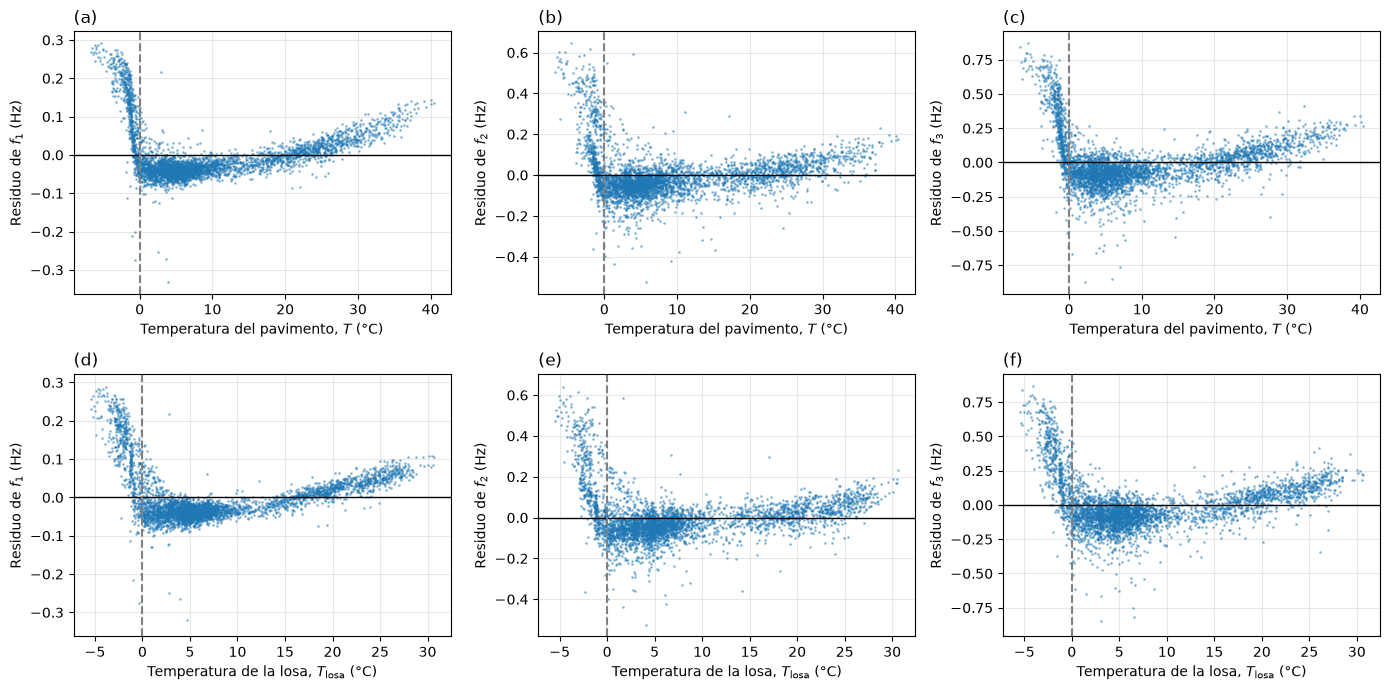

**Figura 6.** Residuos fuera del fold (Ec. 1) de la regresión lineal frente a la temperatura: arriba con la del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey="col")

for i in range(3):
    mode = MODES[i]
    # Row 1: pavement temperature
    axes[0][i].plot(training["T"], training[f"res_pavement_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[0][i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    # Row 2: slab temperature
    axes[1][i].plot(training["T_slab"], training[f"res_slab_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[1][i].set_xlabel("Temperatura de la losa, $T_\\mathrm{losa}$ (°C)")
    for row in range(2):
        axes[row][i].axhline(0, color="black", linewidth=1)
        axes[row][i].axvline(0, color="gray", linestyle="--")
        axes[row][i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
        axes[row][i].grid(alpha=0.3)

labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
for i in range(3):
    axes[0][i].set_title(labels[i], loc="left")
    axes[1][i].set_title(labels[3 + i], loc="left")

fig.tight_layout()
show_figure(fig, 6, "Residuos fuera del fold (Ec. 1) de la regresión lineal frente a la temperatura: arriba con la "
            "del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, "
            "(f) $f_3$). La línea discontinua marca 0 °C.")

**Qué se ve:**

- **Mejora poco sobre la media** (Tabla 6): en $f_1$ el RMSE baja de 0.099 a 0.071 Hz y en $f_3$ de 0.250 a 0.192 Hz. En $f_2$ no cambia (0.120 Hz), y sobre 0 °C es peor que la media.
- **Bajo 0 °C el error es unas tres veces el de sobre 0 °C** en los tres modos (por ejemplo, $f_1$: 0.145 frente a 0.044 Hz).
- **Los residuos tienen forma** (Figura 6): positivos bajo 0 °C (el modelo se queda corto con el puente congelado), negativos entre 0 y unos 15 °C y otra vez positivos con calor. Una recta no puede seguir el quiebre en 0 °C: los puntos de invierno la inclinan y falla en todo el rango.
- **Dispersión vertical bajo 0 °C:** con la misma temperatura, el residuo cambia mucho (en $f_1$ a −2 °C, de 0 a 0.25 Hz). Ningún modelo que use solo la temperatura del momento puede corregir eso, porque a la misma entrada le corresponden frecuencias distintas.
- **Losa frente a pavimento:** la losa es apenas mejor (0.002 a 0.003 Hz en $f_1$ y $f_3$) y los residuos tienen la misma forma con las dos. La diferencia es pequeña frente al error bajo 0 °C.

**Qué le falta al modelo:**

1. Poder cambiar de pendiente en 0 °C.
2. Información que distinga dos mediciones con la misma temperatura bajo 0 °C.

---
<a id="sec5"></a>
## 5. Dos pendientes: una sobre 0 °C y otra bajo 0 °C

Se ataca primero lo que le falta al modelo en el punto 1. Se agrega una variable, la **temperatura bajo cero**, $\min(T, 0)$: vale $T$ cuando la temperatura es negativa y 0 cuando es positiva.

$$
\hat{f}_m = \beta_0 + \beta_1 \, T + \beta_2 \, \min(T, 0)
\tag{4}
$$

donde $\beta_2$ es el cambio de pendiente bajo 0 °C.

- Sobre 0 °C, $\min(T, 0) = 0$ y la pendiente es $\beta_1$.
- Bajo 0 °C, $\min(T, 0) = T$ y la pendiente es $\beta_1 + \beta_2$.

Sigue siendo una regresión lineal, con una variable más. Se ajusta con las dos temperaturas, igual que en el paso 4.

In [16]:
# 1. New variable: temperature below 0 °C (0 when the temperature is positive)
training["T_below_zero"] = np.minimum(training["T"], 0)
training["T_slab_below_zero"] = np.minimum(training["T_slab"], 0)

# 2. Out-of-fold residuals (Eq. 1) of the two-slope model, with each temperature
for mode in MODES:
    predictions = cross_validate("Lineal", ["T", "T_below_zero"], mode)
    training[f"res_pavement_2s_f{mode}"] = training[f"f{mode}"] - predictions

    predictions = cross_validate("Lineal", ["T_slab", "T_slab_below_zero"], mode)
    training[f"res_slab_2s_f{mode}"] = training[f"f{mode}"] - predictions

# 3. RMSE of the straight line (step 4) and of the two-slope model
#    (label in the table, short name of the residual columns)
COMPARED = [("Una pendiente, T del pavimento", "pavement"),
            ("Dos pendientes, T del pavimento", "pavement_2s"),
            ("Una pendiente, T de la losa", "slab"),
            ("Dos pendientes, T de la losa", "slab_2s")]
rows = []
for mode in MODES:
    for model_label, short_name in COMPARED:
        residuals = training[f"res_{short_name}_f{mode}"]
        rows.append({
            "Modo": mode,
            "Modelo": model_label,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
        })
show_table(pd.DataFrame(rows), 7, "RMSE (Ec. 2) de la validación cruzada por semanas: una pendiente (Ec. 3) y dos "
           "pendientes (Ec. 4), con la temperatura del pavimento o de la losa.")

**Tabla 7.** RMSE (Ec. 2) de la validación cruzada por semanas: una pendiente (Ec. 3) y dos pendientes (Ec. 4), con la temperatura del pavimento o de la losa.

Modo,Modelo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,"Una pendiente, T del pavimento",0.071,0.145,0.044
1,"Dos pendientes, T del pavimento",0.041,0.081,0.026
1,"Una pendiente, T de la losa",0.069,0.139,0.043
1,"Dos pendientes, T de la losa",0.038,0.075,0.024
2,"Una pendiente, T del pavimento",0.120,0.233,0.081
2,"Dos pendientes, T del pavimento",0.086,0.144,0.068
2,"Una pendiente, T de la losa",0.119,0.231,0.081
2,"Dos pendientes, T de la losa",0.081,0.132,0.067
3,"Una pendiente, T del pavimento",0.192,0.368,0.132
3,"Dos pendientes, T del pavimento",0.121,0.198,0.100


In [17]:
# Slopes of the two-slope model (Eq. 4), fitted with all the training measurements
rows = []
for mode in MODES:
    for temperature_label, features in [("Pavimento", ["T", "T_below_zero"]),
                                        ("Losa", ["T_slab", "T_slab_below_zero"])]:
        model = LinearRegression()
        model.fit(training[features], training[f"f{mode}"])
        beta_1 = model.coef_[0]
        beta_2 = model.coef_[1]
        rows.append({
            "Modo": mode,
            "Temperatura": temperature_label,
            "β0 (Hz)": model.intercept_,
            "Pendiente sobre 0 °C, β1 (Hz/°C)": beta_1,
            "Pendiente bajo 0 °C, β1 + β2 (Hz/°C)": beta_1 + beta_2,
        })
show_table(pd.DataFrame(rows), 8, "Coeficientes del modelo de dos pendientes (Ec. 4) ajustado con todo el "
           "entrenamiento.", decimals=4)

**Tabla 8.** Coeficientes del modelo de dos pendientes (Ec. 4) ajustado con todo el entrenamiento.

Modo,Temperatura,β0 (Hz),"Pendiente sobre 0 °C, β1 (Hz/°C)","Pendiente bajo 0 °C, β1 + β2 (Hz/°C)"
1,Pavimento,4.0253,-0.0046,-0.0901
1,Losa,4.0270,-0.0056,-0.0898
2,Pavimento,5.1641,0.0017,-0.1187
2,Losa,5.1588,0.0023,-0.1268
3,Pavimento,10.1842,-0.0100,-0.2255
3,Losa,10.1855,-0.0120,-0.2246


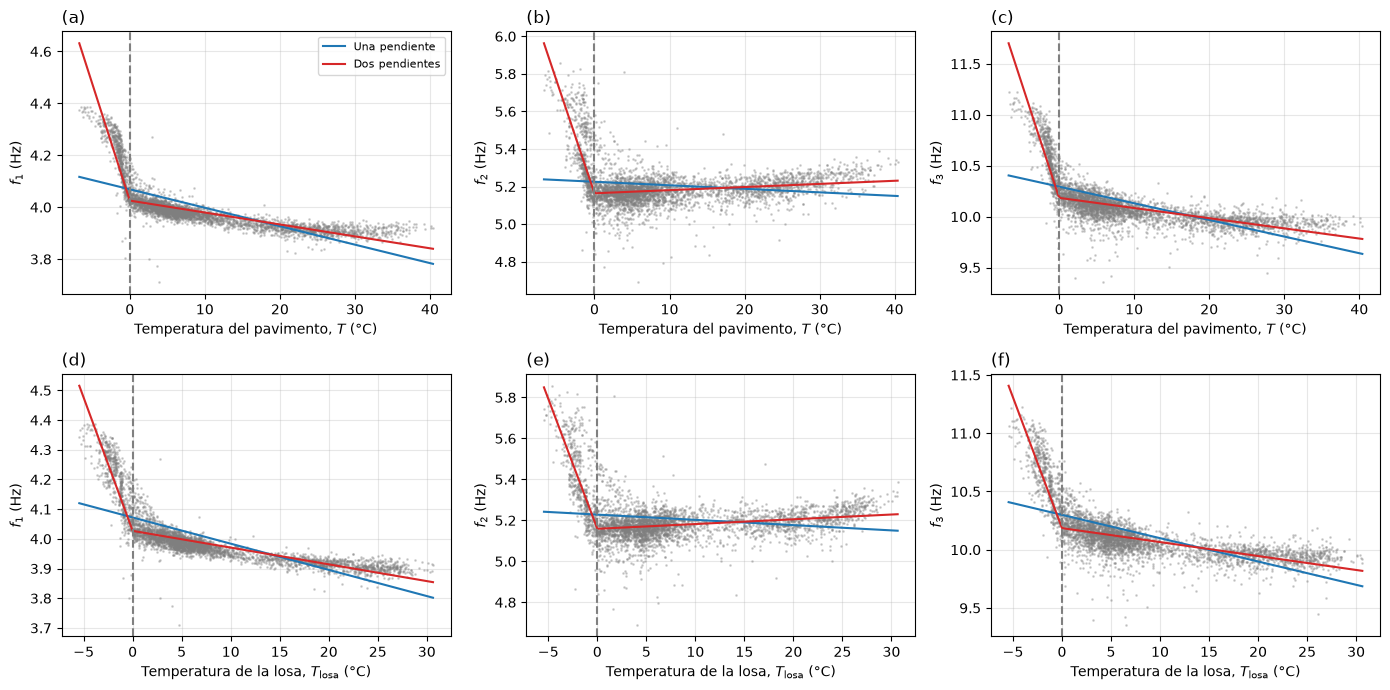

**Figura 7.** Entrenamiento (gris) y rectas ajustadas con una pendiente (Ec. 3, azul) y con dos pendientes (Ec. 4, rojo): arriba con la temperatura del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.

In [18]:
# Fitted lines over the measurements: one slope (Eq. 3) and two slopes (Eq. 4)
#    (temperature column, its below-zero column, axis label)
TEMPERATURES = [("T", "T_below_zero", "Temperatura del pavimento, $T$ (°C)"),
                ("T_slab", "T_slab_below_zero", "Temperatura de la losa, $T_\\mathrm{losa}$ (°C)")]
labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row in range(2):
    temperature, below_name, xlabel = TEMPERATURES[row]

    # Temperatures where the lines are drawn
    grid = pd.DataFrame()
    grid[temperature] = np.linspace(training[temperature].min(), training[temperature].max(), 200)
    grid[below_name] = np.minimum(grid[temperature], 0)

    for i in range(3):
        column = f"f{MODES[i]}"
        one_slope = LinearRegression()
        one_slope.fit(training[[temperature]], training[column])
        two_slopes = LinearRegression()
        two_slopes.fit(training[[temperature, below_name]], training[column])

        ax = axes[row][i]
        ax.plot(training[temperature], training[column], ".", markersize=2, alpha=0.3, color="tab:gray")
        ax.plot(grid[temperature], one_slope.predict(grid[[temperature]]), color="tab:blue", label="Una pendiente")
        ax.plot(grid[temperature], two_slopes.predict(grid[[temperature, below_name]]), color="tab:red",
                label="Dos pendientes")
        ax.axvline(0, color="gray", linestyle="--")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(f"$f_{MODES[i]}$ (Hz)")
        ax.set_title(labels[3 * row + i], loc="left")
        ax.grid(alpha=0.3)
axes[0][0].legend(fontsize=8)

fig.tight_layout()
show_figure(fig, 7, "Entrenamiento (gris) y rectas ajustadas con una pendiente (Ec. 3, azul) y con dos pendientes "
            "(Ec. 4, rojo): arriba con la temperatura del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con "
            "la de la losa ((d) $f_1$, (e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.")

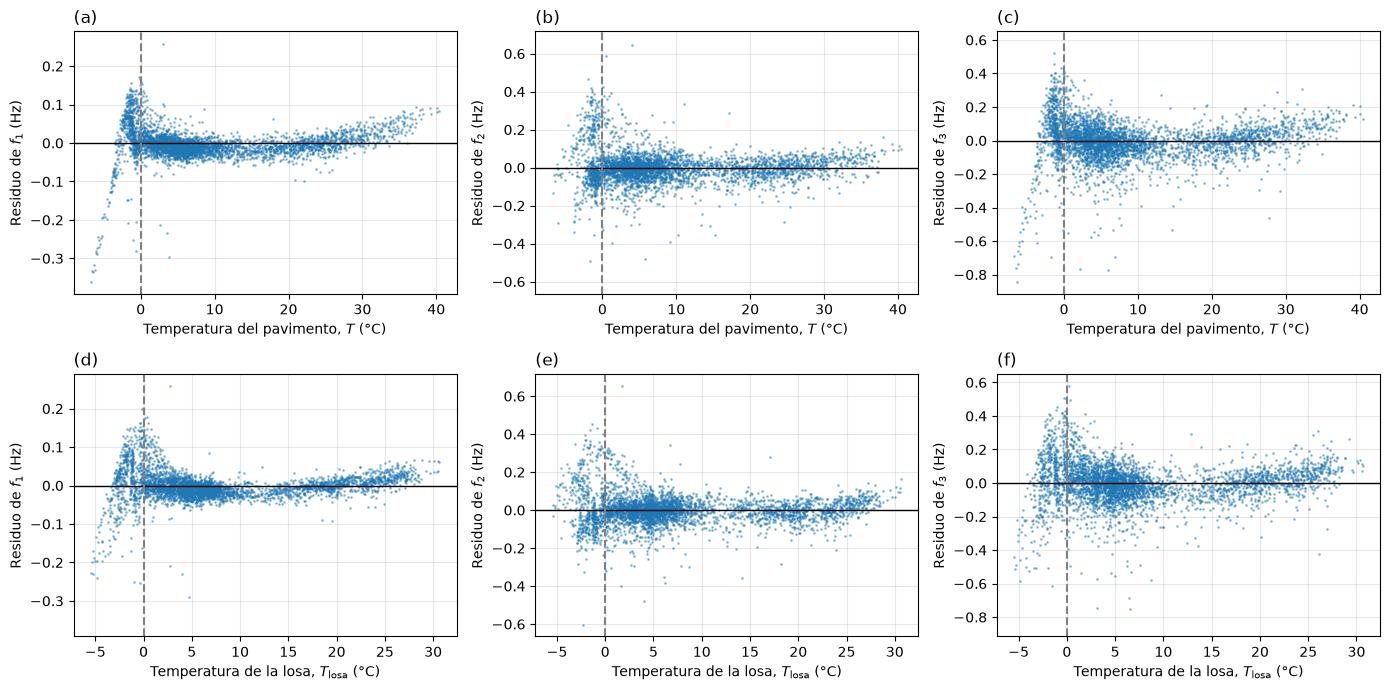

**Figura 8.** Residuos fuera del fold (Ec. 1) del modelo de dos pendientes (Ec. 4) frente a la temperatura: arriba con la del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey="col")

for i in range(3):
    mode = MODES[i]
    # Row 1: pavement temperature
    axes[0][i].plot(training["T"], training[f"res_pavement_2s_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[0][i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    # Row 2: slab temperature
    axes[1][i].plot(training["T_slab"], training[f"res_slab_2s_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[1][i].set_xlabel("Temperatura de la losa, $T_\\mathrm{losa}$ (°C)")
    for row in range(2):
        axes[row][i].axhline(0, color="black", linewidth=1)
        axes[row][i].axvline(0, color="gray", linestyle="--")
        axes[row][i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
        axes[row][i].grid(alpha=0.3)

for i in range(3):
    axes[0][i].set_title(labels[i], loc="left")
    axes[1][i].set_title(labels[3 + i], loc="left")

fig.tight_layout()
show_figure(fig, 8, "Residuos fuera del fold (Ec. 1) del modelo de dos pendientes (Ec. 4) frente a la temperatura: "
            "arriba con la del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, "
            "(e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.")

**Qué se ve:**

- **El error baja mucho** (Tabla 7). Con el pavimento, el RMSE total pasa de 0.071 a 0.041 Hz en $f_1$, de 0.120 a 0.086 Hz en $f_2$ y de 0.192 a 0.121 Hz en $f_3$. Bajo 0 °C se reduce casi a la mitad (en $f_1$, de 0.145 a 0.081 Hz).
- **Bajo 0 °C la pendiente es mucho mayor** (Tabla 8): en $f_1$, −0.090 Hz/°C frente a −0.005 Hz/°C sobre 0 °C, unas 20 veces más. En $f_2$ incluso cambia de signo. El quiebre en 0 °C es real y el modelo ahora lo sigue (Figura 7).
- **Lo que queda en los residuos** (Figura 8):
  - Con las temperaturas más frías (bajo −3 °C), los residuos son negativos: la recta sigue subiendo, pero las frecuencias medidas se estabilizan.
  - Entre −2 y 3 °C quedan residuos positivos grandes (hasta 0.15 Hz en $f_1$ y 0.4 Hz en $f_2$ y $f_3$): con la misma temperatura cerca de 0 °C, unas veces el puente está mucho más rígido que otras.
- **Losa frente a pavimento:** la losa sigue siendo apenas mejor (0.001 a 0.005 Hz) y los residuos tienen la misma forma.

**Qué le falta al modelo:** el punto 1 quedó resuelto en gran parte. Queda el punto 2: cerca de 0 °C, la temperatura del momento no distingue un puente rígido de uno que no lo está.

---
<a id="sec6"></a>
## 6. ¿Importa la temperatura de las horas anteriores?

**Hipótesis:** el puente no cambia de temperatura al mismo ritmo que la superficie del pavimento. Si viene de varios días de helada, el asfalto y la estructura siguen fríos y rígidos aunque el pavimento ya esté cerca de 0 °C. Si viene de días templados, está menos rígido con la misma temperatura.

Si es cierto, cerca de 0 °C el residuo del modelo de dos pendientes (paso 5) debería ser mayor cuanto más fría haya sido la temperatura de las horas anteriores.

Una medida simple de esa historia es la **temperatura media de las últimas $w$ horas**:

$$
\bar{T}_{w,i} = \frac{1}{n_{w,i}} \sum_{j\,:\; t_i - w < t_j \le t_i} T_j
\tag{5}
$$

donde $T_j$ es la temperatura de la medición $j$, $t_j$ su hora y $n_{w,i}$ el número de mediciones con temperatura en las últimas $w$ horas.

- Usa solo la medición actual y las anteriores, así que se puede calcular mientras se monitorea.
- Se calcula con todas las mediciones que tienen temperatura, aunque no tengan frecuencia, porque solo hace falta la temperatura.
- Se calcula igual con la temperatura de la losa.

Se empieza con un día ($w = 24$ h) y con las mediciones cercanas a 0 °C, entre −2 y 3 °C, donde el paso 5 dejó los residuos grandes.

In [20]:
# 1. Mean temperature of the last w hours (Eq. 5), with all the measurements in time order
WINDOWS = [6, 12, 24, 48, 72, 168]
for w in WINDOWS:
    data[f"T_mean_{w}h"] = data.rolling(f"{w}h", on="start")["T"].mean()
    data[f"T_slab_mean_{w}h"] = data.rolling(f"{w}h", on="start")["T_slab"].mean()

    # Same values for the training measurements (training keeps the row labels of data)
    training[f"T_mean_{w}h"] = data.loc[training.index, f"T_mean_{w}h"]
    training[f"T_slab_mean_{w}h"] = data.loc[training.index, f"T_slab_mean_{w}h"]

# 2. Training measurements near 0 °C (from -2 to 3 °C), with each temperature
near_zero_pavement = (training["T"] >= -2) & (training["T"] <= 3)
near_zero_slab = (training["T_slab"] >= -2) & (training["T_slab"] <= 3)
print(f"Measurements near 0 °C: pavement {near_zero_pavement.sum()}, slab {near_zero_slab.sum()}")

Measurements near 0 °C: pavement 1091, slab 1079


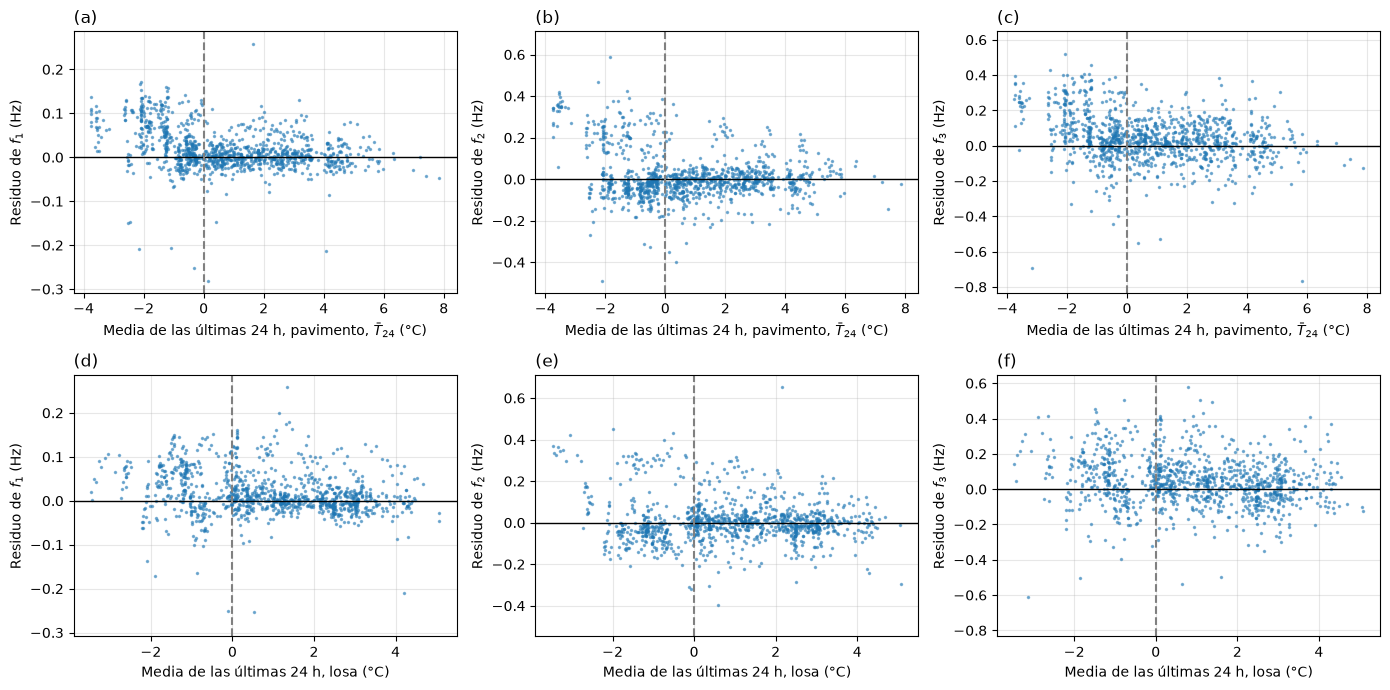

**Figura 9.** Residuos fuera del fold (Ec. 1) del modelo de dos pendientes (Ec. 4) de las mediciones con temperatura entre −2 y 3 °C, frente a la temperatura media de las últimas 24 h (Ec. 5): arriba con la del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, (f) $f_3$). La línea discontinua marca 0 °C.

In [21]:
near_pavement = training[near_zero_pavement]
near_slab = training[near_zero_slab]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey="col")
for i in range(3):
    mode = MODES[i]
    # Row 1: pavement temperature
    axes[0][i].plot(near_pavement["T_mean_24h"], near_pavement[f"res_pavement_2s_f{mode}"], ".",
                    markersize=3, alpha=0.5)
    axes[0][i].set_xlabel("Media de las últimas 24 h, pavimento, $\\bar{T}_{24}$ (°C)")
    # Row 2: slab temperature
    axes[1][i].plot(near_slab["T_slab_mean_24h"], near_slab[f"res_slab_2s_f{mode}"], ".",
                    markersize=3, alpha=0.5)
    axes[1][i].set_xlabel("Media de las últimas 24 h, losa (°C)")
    for row in range(2):
        axes[row][i].axhline(0, color="black", linewidth=1)
        axes[row][i].axvline(0, color="gray", linestyle="--")
        axes[row][i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
        axes[row][i].grid(alpha=0.3)

for i in range(3):
    axes[0][i].set_title(labels[i], loc="left")
    axes[1][i].set_title(labels[3 + i], loc="left")

fig.tight_layout()
show_figure(fig, 9, "Residuos fuera del fold (Ec. 1) del modelo de dos pendientes (Ec. 4) de las mediciones con "
            "temperatura entre −2 y 3 °C, frente a la temperatura media de las últimas 24 h (Ec. 5): arriba con la "
            "del pavimento ((a) $f_1$, (b) $f_2$, (c) $f_3$) y abajo con la de la losa ((d) $f_1$, (e) $f_2$, "
            "(f) $f_3$). La línea discontinua marca 0 °C.")

Para ver si el resultado depende de haber elegido un día, se repite con otras ventanas, desde 6 horas hasta una semana. Se mide la correlación entre el residuo y $\bar{T}_w$ en las mismas mediciones cercanas a 0 °C: si la hipótesis es cierta, debe ser negativa.

In [22]:
# Correlation between the residual of the two-slope model and the mean of the last w hours, near 0 °C
rows = []
for temperature_label, prefix, short_name, near_data in [("Pavimento", "T", "pavement_2s", near_pavement),
                                                          ("Losa", "T_slab", "slab_2s", near_slab)]:
    for w in WINDOWS:
        row = {"Temperatura": temperature_label, "Ventana, w (h)": w}
        for mode in MODES:
            residuals = near_data[f"res_{short_name}_f{mode}"]
            row[f"f{mode}"] = residuals.corr(near_data[f"{prefix}_mean_{w}h"])
        rows.append(row)
show_table(pd.DataFrame(rows), 9, "Correlación entre el residuo del modelo de dos pendientes (Ec. 4) y la "
           "temperatura media de las últimas $w$ horas (Ec. 5), en las mediciones con temperatura entre −2 y 3 °C.",
           decimals=2)

**Tabla 9.** Correlación entre el residuo del modelo de dos pendientes (Ec. 4) y la temperatura media de las últimas $w$ horas (Ec. 5), en las mediciones con temperatura entre −2 y 3 °C.

Temperatura,"Ventana, w (h)",f1,f2,f3
Pavimento,6,-0.34,-0.13,-0.27
Pavimento,12,-0.32,-0.16,-0.27
Pavimento,24,-0.35,-0.21,-0.29
Pavimento,48,-0.37,-0.28,-0.29
Pavimento,72,-0.40,-0.35,-0.31
Pavimento,168,-0.44,-0.51,-0.37
Losa,6,-0.21,-0.02,-0.16
Losa,12,-0.18,-0.05,-0.14
Losa,24,-0.23,-0.12,-0.18
Losa,48,-0.24,-0.21,-0.17


**Qué se ve:**

- **La hipótesis se cumple con el pavimento** (Figura 9a–c). Con la misma temperatura cerca de 0 °C, si la media de las últimas 24 h fue negativa, los residuos son casi siempre positivos (en $f_1$, hasta 0.15 Hz): el puente está más rígido de lo que predice el modelo. Si fue positiva, los residuos quedan alrededor de 0.
- **El efecto no es una recta:** los residuos suben cuando $\bar{T}_{24}$ baja de 0 °C y casi no cambian sobre 0 °C. Es un quiebre parecido al del paso 5.
- **La correlación es negativa en todos los casos** (Tabla 9), como pide la hipótesis, y crece con ventanas más largas. En $f_2$ pasa de −0.13 con 6 h a −0.51 con una semana: lo que más importa en $f_2$ es si el puente viene de varios días de helada, no solo del día anterior.
- **Con la losa la relación es más débil** (Figura 9d–f; Tabla 9, de −0.02 a −0.46). Una posible explicación es que la losa ya cambia de temperatura con retraso, así que su valor actual ya contiene parte de la historia.
- **No lo explica todo:** en $f_2$ (Figura 9b) hay mediciones con $\bar{T}_{24}$ entre −2 y 0 °C y residuo cercano a 0, junto a otras con residuo de 0.2 a 0.3 Hz.

**Decisión:** el modelo necesita la **historia de la temperatura**, no solo la temperatura del momento. Falta decidir cómo entra al modelo: qué ventanas usar y con qué forma, porque el efecto tiene un quiebre en 0 °C.

---
<a id="sec7"></a>
## 7. La historia de la temperatura en la regresión lineal

### 7.1 ¿Qué ventanas?

El paso 6 mostró que el efecto de la historia tiene un quiebre en 0 °C. Se le da la misma forma que a la temperatura del momento en el paso 5: la media de las últimas $w$ horas y su parte bajo cero.

$$
\hat{f}_m = \beta_0 + \beta_1 \, T + \beta_2 \, \min(T, 0) + \beta_3 \, \bar{T}_w + \beta_4 \, \min(\bar{T}_w, 0)
\tag{6}
$$

donde $\bar{T}_w$ es la media de las últimas $w$ horas (Ec. 5), $\beta_3$ su pendiente y $\beta_4$ el cambio de esa pendiente cuando la media es negativa.

No se sabe qué ventana conviene. Se prueba cada una por separado y todas juntas (un par de términos por ventana), con las dos temperaturas.

In [23]:
# 1. History below 0 °C: min(mean of the last w hours, 0), with each temperature
for w in WINDOWS:
    training[f"T_mean_{w}h_below_zero"] = np.minimum(training[f"T_mean_{w}h"], 0)
    training[f"T_slab_mean_{w}h_below_zero"] = np.minimum(training[f"T_slab_mean_{w}h"], 0)


# 2. Input variables: two slopes (step 5) plus the history of the given windows (Eq. 6)
def linear_features(prefix, windows):
    features = [prefix, f"{prefix}_below_zero"]
    for w in windows:
        features.append(f"{prefix}_mean_{w}h")
        features.append(f"{prefix}_mean_{w}h_below_zero")
    return features


# 3. Options: no history (step 5), one window, all the windows
OPTIONS = [("Dos pendientes (paso 5)", [])]
for w in WINDOWS:
    OPTIONS.append((f"+ ventana de {w} h", [w]))
OPTIONS.append(("+ todas las ventanas", WINDOWS))

# 4. Validation RMSE (Eq. 2) of each option, in each mode and with each temperature
TEMPERATURE_PREFIXES = [("Pavimento", "T"), ("Losa", "T_slab")]
rows = []
for temperature_label, prefix in TEMPERATURE_PREFIXES:
    for option_label, windows in OPTIONS:
        row = {"Temperatura": temperature_label, "Variables": option_label}
        for mode in MODES:
            predictions = cross_validate("Lineal", linear_features(prefix, windows), mode)
            row[f"RMSE f{mode} (Hz)"] = rmse(training[f"f{mode}"] - predictions)
        rows.append(row)
linear_table = pd.DataFrame(rows)
show_table(linear_table, 10, "RMSE total (Ec. 2) de la validación cruzada por semanas de la regresión lineal con "
           "dos pendientes (Ec. 4) más la historia de la temperatura (Ec. 6), con cada ventana o con todas.",
           decimals=4)

**Tabla 10.** RMSE total (Ec. 2) de la validación cruzada por semanas de la regresión lineal con dos pendientes (Ec. 4) más la historia de la temperatura (Ec. 6), con cada ventana o con todas.

Temperatura,Variables,RMSE f1 (Hz),RMSE f2 (Hz),RMSE f3 (Hz)
Pavimento,Dos pendientes (paso 5),0.0406,0.0856,0.1213
Pavimento,+ ventana de 6 h,0.0403,0.0851,0.1216
Pavimento,+ ventana de 12 h,0.0390,0.0851,0.1205
Pavimento,+ ventana de 24 h,0.0368,0.0828,0.1158
Pavimento,+ ventana de 48 h,0.0369,0.0780,0.1149
Pavimento,+ ventana de 72 h,0.0367,0.0736,0.1142
Pavimento,+ ventana de 168 h,0.0392,0.0628,0.1177
Pavimento,+ todas las ventanas,0.0375,0.0622,0.1155
Losa,Dos pendientes (paso 5),0.0376,0.0814,0.1199
Losa,+ ventana de 6 h,0.0369,0.0816,0.1184


Measurements below -3 °C: 74
f1: best option '+ ventana de 72 h', mean residual below -3 °C = -0.102 Hz
f2: best option '+ todas las ventanas', mean residual below -3 °C = -0.034 Hz
f3: best option '+ ventana de 72 h', mean residual below -3 °C = -0.212 Hz


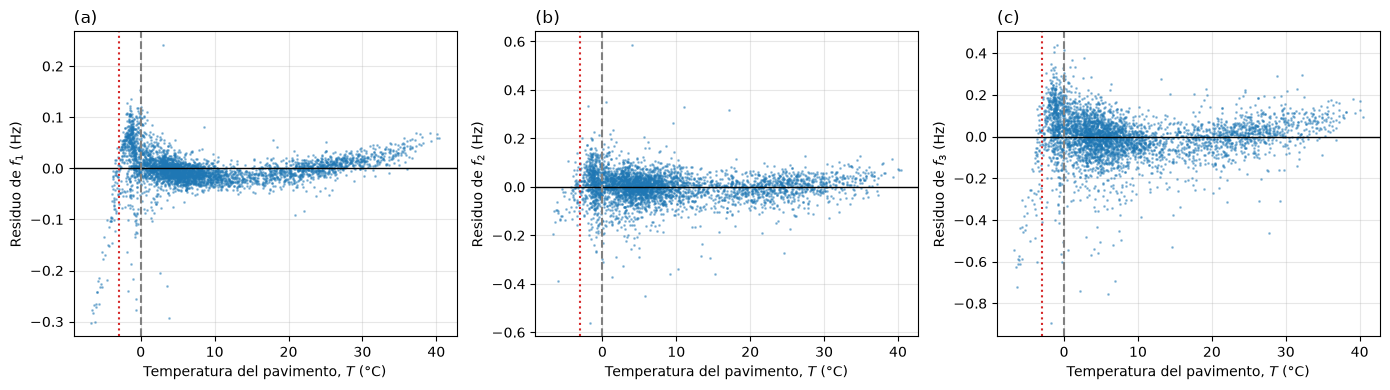

**Figura 10.** Residuos fuera del fold (Ec. 1) de la mejor regresión lineal con historia de cada modo (Tabla 10, pavimento) frente a la temperatura: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua marca 0 °C y la punteada −3 °C.

In [24]:
# Best option of each mode with the pavement temperature (Table 10), without the two-slope model
best_linear = {}
for mode in MODES:
    column = f"RMSE f{mode} (Hz)"
    pavement_rows = linear_table[(linear_table["Temperatura"] == "Pavimento")
                                 & (linear_table["Variables"] != "Dos pendientes (paso 5)")]
    best_row = pavement_rows.loc[pavement_rows[column].idxmin()]
    for option_label, windows in OPTIONS:
        if option_label == best_row["Variables"]:
            best_linear[mode] = (option_label, windows)

    # Out-of-fold residuals (Eq. 1) of that option
    predictions = cross_validate("Lineal", linear_features("T", best_linear[mode][1]), mode)
    training[f"res_linear_history_f{mode}"] = training[f"f{mode}"] - predictions

# Mean residual of the coldest measurements (below -3 °C)
coldest = training["T"] < -3
print(f"Measurements below -3 °C: {coldest.sum()}")
for mode in MODES:
    mean_residual = training.loc[coldest, f"res_linear_history_f{mode}"].mean()
    print(f"f{mode}: best option '{best_linear[mode][0]}', mean residual below -3 °C = {mean_residual:+.3f} Hz")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for i in range(3):
    mode = MODES[i]
    axes[i].plot(training["T"], training[f"res_linear_history_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axhline(0, color="black", linewidth=1)
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].axvline(-3, color="tab:red", linestyle=":")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 10, "Residuos fuera del fold (Ec. 1) de la mejor regresión lineal con historia de cada modo "
            "(Tabla 10, pavimento) frente a la temperatura: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua "
            "marca 0 °C y la punteada −3 °C.")

**Qué se ve:**

- **La historia mejora la regresión lineal** (Tabla 10, pavimento). El RMSE de $f_2$ baja de 0.0856 a 0.0622 Hz (−27 %) con todas las ventanas. En $f_1$ y $f_3$ la mejora es menor: de 0.0406 a 0.0367 Hz (−10 %) y de 0.1213 a 0.1142 Hz (−6 %), con 72 h.
- **Cada modo pide otra ventana:** $f_1$ casi lo mismo con 24, 48 o 72 h; $f_2$ con una semana o todas; $f_3$ con 72 h.
- **Pavimento frente a losa:** con la historia, el pavimento es mejor o igual en los tres modos (mejor opción: $f_1$ 0.0367 frente a 0.0369 Hz, $f_2$ 0.0622 frente a 0.0634 Hz, $f_3$ 0.1142 frente a 0.1172 Hz). La ventaja de la losa en los pasos 4 y 5 era pequeña; la historia del pavimento da más información.
- **Lo que queda en los residuos** (Figura 10):
  - **Bajo −3 °C** (74 mediciones), los residuos son negativos: en promedio −0.102 Hz en $f_1$, −0.034 Hz en $f_2$ y −0.212 Hz en $f_3$. Las rectas siguen subiendo con el frío, pero las frecuencias medidas dejan de subir.
  - En $f_1$, los residuos suben con el calor sobre unos 25 °C (hasta +0.05 Hz a 40 °C): la relación también se curva en ese extremo.
  - Cerca de 0 °C sigue la dispersión.

**Decisión:** desde aquí se usa solo la **temperatura del pavimento**.

### 7.2 ¿Frío acumulado?

**Hipótesis:** bajo 0 °C, la rigidez depende de cuánto se ha congelado el pavimento en profundidad, y eso depende del frío acumulado más que de una media. El frío acumulado se mide con el **índice de congelamiento**, en °C·h:

$$
I_i = \max\left(0,\; I_{i-1} - T_i \, \Delta t_i\right)
\tag{7}
$$

donde $I_i$ es el índice en la medición $i$, $T_i$ la temperatura del pavimento y $\Delta t_i$ las horas desde la medición anterior.

- Crece mientras la temperatura está bajo 0 °C, baja con el deshielo y nunca es negativo.
- Se calcula, como las medias, con todas las mediciones que tienen temperatura, en orden de tiempo.
- La profundidad congelada crece aproximadamente con $\sqrt{I}$ (ecuación de Stefan), así que se agrega $\sqrt{I}$ a la mejor regresión de cada modo (Tabla 10).

In [25]:
# 1. Freezing index (Eq. 7), with all the measurements in time order
freezing_index = []
index_value = 0
previous_start = None
for _, row in data.iterrows():
    if previous_start is not None and not np.isnan(row["T"]):
        hours = (row["start"] - previous_start).total_seconds() / 3600
        index_value = max(0, index_value - row["T"] * hours)
    freezing_index.append(index_value)
    previous_start = row["start"]
data["freezing_index"] = freezing_index
training["sqrt_freezing_index"] = np.sqrt(data.loc[training.index, "freezing_index"])

# 2. Best linear option of each mode, without and with the square root of the index
rows = []
for mode in MODES:
    option_label, windows = best_linear[mode]
    features = linear_features("T", windows)
    for variables_label, model_features in [("Sin el índice", features),
                                            ("Con raíz del índice", features + ["sqrt_freezing_index"])]:
        residuals = training[f"f{mode}"] - cross_validate("Lineal", model_features, mode)
        rows.append({
            "Modo": mode,
            "Regresión (Tabla 10)": option_label,
            "Variables": variables_label,
            "RMSE total (Hz)": rmse(residuals),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "Residuo medio bajo −3 °C (Hz)": residuals[coldest].mean(),
        })
show_table(pd.DataFrame(rows), 11, "Mejor regresión lineal con historia de cada modo (Tabla 10, pavimento), sin y "
           "con la raíz del índice de congelamiento (Ec. 7): RMSE de la validación cruzada por semanas (Ec. 2) y "
           "residuo medio de las mediciones bajo −3 °C.", decimals=4)

**Tabla 11.** Mejor regresión lineal con historia de cada modo (Tabla 10, pavimento), sin y con la raíz del índice de congelamiento (Ec. 7): RMSE de la validación cruzada por semanas (Ec. 2) y residuo medio de las mediciones bajo −3 °C.

Modo,Regresión (Tabla 10),Variables,RMSE total (Hz),RMSE bajo 0 °C (Hz),Residuo medio bajo −3 °C (Hz)
1,+ ventana de 72 h,Sin el índice,0.0367,0.0740,-0.1017
1,+ ventana de 72 h,Con raíz del índice,0.0388,0.0731,-0.1049
2,+ todas las ventanas,Sin el índice,0.0622,0.0827,-0.0344
2,+ todas las ventanas,Con raíz del índice,0.0619,0.0842,-0.0157
3,+ ventana de 72 h,Sin el índice,0.1142,0.1794,-0.2115
3,+ ventana de 72 h,Con raíz del índice,0.1166,0.1770,-0.2191


**Qué se ve** (Tabla 11):

- **La raíz del índice no mejora:** el RMSE empeora en $f_1$ (de 0.0367 a 0.0388 Hz) y en $f_3$ (de 0.1142 a 0.1166 Hz), y en $f_2$ casi no cambia (de 0.0622 a 0.0619 Hz).
- **Los residuos bajo −3 °C siguen negativos** en $f_1$ y $f_3$ (−0.105 y −0.219 Hz). El frío acumulado, con esta forma, no explica que las frecuencias dejen de subir.

**Decisión:** no se usa el índice de congelamiento. La hipótesis no se sostiene con estos datos.

**Qué le falta a la regresión lineal:**

1. Aplanarse con el frío más intenso (bajo −3 °C) y curvarse con el calor ($f_1$).
2. Hay que darle a mano la forma de cada término (el quiebre en 0 °C) y elegir la ventana de cada modo.

Un modelo que aprenda la forma por sí solo podría resolver las dos cosas.

---
<a id="sec8"></a>
## 8. Red neuronal

Una **red neuronal** (perceptrón multicapa) aprende la forma de la relación sin que se le indique. Cada neurona calcula una suma ponderada de sus entradas y le aplica una función de activación:

$$
z = g\left(b + \sum_{j} w_j \, x_j\right), \qquad g(u) = \max(0, u)
\tag{8}
$$

donde $x_j$ son las entradas de la neurona, $w_j$ sus pesos, $b$ su sesgo y $g$ la activación ReLU, que deja pasar los valores positivos y convierte los negativos en 0.

- Cada neurona aporta un quiebre. La red combina muchas y forma una curva con quiebres donde los datos lo piden: no hace falta decirle dónde está el quiebre ni qué ventana usar, y puede aplanarse con el frío más intenso.
- **Entradas:** la temperatura del pavimento y sus medias de 6, 12, 24, 48, 72 y 168 h, sin las partes bajo cero.
- Las entradas y la frecuencia se estandarizan (se les resta la media y se dividen por la desviación estándar de los folds de ajuste), para que todas tengan la misma escala.
- **Hiperparámetros:**
  - Neuronas por capa oculta: una capa de 10 o de 30, dos capas de 30, de 50 o de 100, o tres capas de 30 o de 50.
  - `alpha`: penalización de los pesos grandes, que evita que la red se aprenda el ruido (0.0001, 0.01, 0.1 o 1).
- **Parada temprana:** la red se ajusta por iteraciones. Se separa un 10 % de los folds de ajuste y se para cuando el error en ese 10 % deja de bajar.
- Los pesos empiezan al azar, así que se fija la semilla (42).

Cada combinación se evalúa con la misma validación cruzada por semanas. Tarda varios minutos, así que el resultado se guarda en un archivo y se lee de ahí las siguientes veces.

In [26]:
# 1. Week-blocked cross-validation (step 3) of a neural network
def cross_validate_mlp(features, mode, hidden_layers, alpha):
    column = f"f{mode}"
    predictions = np.zeros(len(training))
    for fold in range(1, N_FOLDS + 1):
        is_validation = (training["fold"] == fold).to_numpy()
        fit_part = training[~is_validation]
        validation_part = training[is_validation]

        # Inputs and frequency scaled with the mean and standard deviation of the fit folds
        scaler = StandardScaler()
        x_fit = scaler.fit_transform(fit_part[features])
        x_validation = scaler.transform(validation_part[features])
        f_mean = fit_part[column].mean()
        f_std = fit_part[column].std()
        y_fit = (fit_part[column] - f_mean) / f_std

        model = MLPRegressor(hidden_layer_sizes=hidden_layers, alpha=alpha, early_stopping=True,
                             max_iter=2000, random_state=SEED)
        model.fit(x_fit, y_fit)
        predictions[is_validation] = model.predict(x_validation) * f_std + f_mean
    return predictions


# 2. Inputs of the flexible models: the pavement temperature and its means (no below-zero parts)
FLEXIBLE_FEATURES = ["T"]
for w in WINDOWS:
    FLEXIBLE_FEATURES.append(f"T_mean_{w}h")

# 3. Hyperparameter combinations
HIDDEN_LAYERS = {"10": (10,), "30": (30,), "30 y 30": (30, 30), "50 y 50": (50, 50), "100 y 100": (100, 100),
                 "30, 30 y 30": (30, 30, 30), "50, 50 y 50": (50, 50, 50)}
ALPHAS = [0.0001, 0.01, 0.1, 1]

# 4. Validation RMSE of every combination (saved in a file the first time)
MLP_FILE = "step_by_step_cache/mlp_cross_validation.csv"
if os.path.exists(MLP_FILE):
    mlp_table = pd.read_csv(MLP_FILE, dtype={"Neuronas por capa oculta": str})
else:
    rows = []
    for layers_label in HIDDEN_LAYERS:
        for alpha in ALPHAS:
            row = {"Neuronas por capa oculta": layers_label, "alpha": alpha}
            for mode in MODES:
                predictions = cross_validate_mlp(FLEXIBLE_FEATURES, mode, HIDDEN_LAYERS[layers_label], alpha)
                row[f"RMSE f{mode} (Hz)"] = rmse(training[f"f{mode}"] - predictions)
            rows.append(row)
    mlp_table = pd.DataFrame(rows)
    os.makedirs("step_by_step_cache", exist_ok=True)
    mlp_table.to_csv(MLP_FILE, index=False)

show_table(mlp_table, 12, "RMSE total (Ec. 2) de la validación cruzada por semanas de la red neuronal con cada "
           "combinación de hiperparámetros, temperatura del pavimento.", decimals=4)

**Tabla 12.** RMSE total (Ec. 2) de la validación cruzada por semanas de la red neuronal con cada combinación de hiperparámetros, temperatura del pavimento.

Neuronas por capa oculta,alpha,RMSE f1 (Hz),RMSE f2 (Hz),RMSE f3 (Hz)
10,0.0001,0.0314,0.0773,0.1062
10,0.0100,0.0312,0.0777,0.1060
10,0.1000,0.0314,0.0778,0.1061
10,1.0000,0.0329,0.0768,0.1117
30,0.0001,0.0323,0.0685,0.1060
30,0.0100,0.0320,0.0686,0.1060
30,0.1000,0.0319,0.0689,0.1059
30,1.0000,0.0327,0.0733,0.1098
30 y 30,0.0001,0.0294,0.0682,0.1038
30 y 30,0.0100,0.0291,0.0681,0.1040


f1: best network 30, 30 y 30, alpha 0.0001; RMSE 0.0274 Hz (best linear 0.0367 Hz); below 0 °C 0.0496 Hz (linear 0.0740 Hz); mean residual below -3 °C -0.031 Hz


f2: best network 100 y 100, alpha 0.0001; RMSE 0.0657 Hz (best linear 0.0622 Hz); below 0 °C 0.0893 Hz (linear 0.0827 Hz); mean residual below -3 °C -0.000 Hz


f3: best network 100 y 100, alpha 0.0001; RMSE 0.1025 Hz (best linear 0.1142 Hz); below 0 °C 0.1468 Hz (linear 0.1794 Hz); mean residual below -3 °C -0.101 Hz


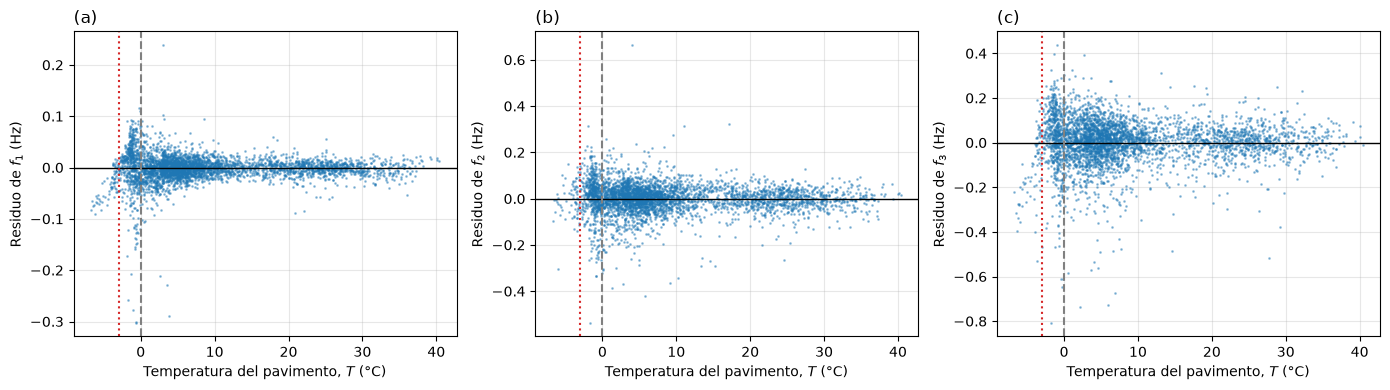

**Figura 11.** Residuos fuera del fold (Ec. 1) de la mejor red neuronal de cada modo (Tabla 12) frente a la temperatura del pavimento: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua marca 0 °C y la punteada −3 °C.

In [27]:
# Out-of-fold residuals of the best network of each mode (Table 12)
best_mlp = {}
for mode in MODES:
    column = f"RMSE f{mode} (Hz)"
    best_mlp[mode] = mlp_table.loc[mlp_table[column].idxmin()]
    hidden_layers = HIDDEN_LAYERS[best_mlp[mode]["Neuronas por capa oculta"]]
    predictions = cross_validate_mlp(FLEXIBLE_FEATURES, mode, hidden_layers, best_mlp[mode]["alpha"])
    training[f"res_mlp_f{mode}"] = training[f"f{mode}"] - predictions

    linear_rmse = rmse(training[f"res_linear_history_f{mode}"])
    mlp_rmse = rmse(training[f"res_mlp_f{mode}"])
    cold_residual = training.loc[coldest, f"res_mlp_f{mode}"].mean()
    print(f"f{mode}: best network {best_mlp[mode]['Neuronas por capa oculta']}, alpha {best_mlp[mode]['alpha']:g}; "
          f"RMSE {mlp_rmse:.4f} Hz (best linear {linear_rmse:.4f} Hz); "
          f"below 0 °C {rmse(training.loc[below_zero, f'res_mlp_f{mode}']):.4f} Hz "
          f"(linear {rmse(training.loc[below_zero, f'res_linear_history_f{mode}']):.4f} Hz); "
          f"mean residual below -3 °C {cold_residual:+.3f} Hz")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for i in range(3):
    mode = MODES[i]
    axes[i].plot(training["T"], training[f"res_mlp_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axhline(0, color="black", linewidth=1)
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].axvline(-3, color="tab:red", linestyle=":")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 11, "Residuos fuera del fold (Ec. 1) de la mejor red neuronal de cada modo (Tabla 12) frente a la "
            "temperatura del pavimento: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua marca 0 °C y la "
            "punteada −3 °C.")

**Qué se ve:**

- **La red es mejor en $f_1$ y $f_3$** que la mejor regresión lineal (Tabla 12):
  - $f_1$: 0.0274 frente a 0.0367 Hz (−25 %); bajo 0 °C, 0.0496 frente a 0.0740 Hz.
  - $f_3$: 0.1025 frente a 0.1142 Hz (−10 %); bajo 0 °C, 0.1468 frente a 0.1794 Hz.
- **En $f_2$ sigue ganando la regresión lineal:** 0.0622 frente a 0.0657 Hz. La forma que se le dio (un quiebre en 0 °C en cada media) le sirve bien a $f_2$.
- **El frío intenso mejora:** el residuo medio bajo −3 °C pasa de −0.102 a −0.031 Hz en $f_1$ y de −0.212 a −0.101 Hz en $f_3$ (Figura 11). La curvatura de $f_1$ con el calor desaparece.
- **Hiperparámetros:** `alpha` = 1 empeora en todos los casos; con los demás valores casi no cambia. Las redes de dos o tres capas son mejores que las de una. Entre las redes grandes las diferencias son pequeñas (menos de 0.003 Hz).
- **Lo que queda:** cerca de 0 °C sigue la dispersión, sobre todo en $f_2$ y $f_3$ (Figura 11b y 11c).

---
<a id="sec9"></a>
## 9. Random forest

La red forma curvas con transiciones suaves entre sus quiebres. El congelamiento puede producir cambios bruscos de rigidez, así que se prueba un modelo de otra naturaleza, que divide las variables por rangos.

Un **árbol de regresión** divide las mediciones de entrenamiento con preguntas sobre una variable (por ejemplo, "¿$\bar{T}_{72}$ < −0.5 °C?") hasta llegar a grupos pequeños, las **hojas**, y predice la media de la frecuencia de la hoja. Un **random forest** promedia $B$ árboles:

$$
\hat{f}_m = \frac{1}{B} \sum_{b=1}^{B} h_b(\mathbf{x})
\tag{9}
$$

donde $h_b(\mathbf{x})$ es la predicción del árbol $b$ para las variables de entrada $\mathbf{x}$.

- Cada árbol se ajusta con una muestra al azar de las mediciones y, en cada división, elige entre unas pocas variables al azar. Así los árboles son distintos y su promedio tiene menos error que uno solo.
- **Entradas:** las mismas de la red (paso 8). No hace falta estandarizarlas: cada pregunta compara una sola variable con un valor.
- $B$ = 200 árboles y semilla 42.
- **Hiperparámetros:**
  - Mínimo de mediciones por hoja (1, 5, 10, 20 o 50): con hojas más grandes, los árboles son más cortos y se aprenden menos el ruido.
  - Variables por división (1, 3, 5 o 7): cuántas variables al azar compiten en cada pregunta.
- **Limitación:** fuera del rango del entrenamiento predice un valor constante. Las temperaturas de prueba quedan dentro del rango (paso 3.1).

In [28]:
# 1. Week-blocked cross-validation (step 3) of a random forest
def cross_validate_forest(features, mode, min_samples_leaf, max_features):
    column = f"f{mode}"
    predictions = np.zeros(len(training))
    for fold in range(1, N_FOLDS + 1):
        is_validation = (training["fold"] == fold).to_numpy()
        fit_part = training[~is_validation]
        validation_part = training[is_validation]

        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=min_samples_leaf,
                                      max_features=max_features, random_state=SEED, n_jobs=-1)
        model.fit(fit_part[features], fit_part[column])
        predictions[is_validation] = model.predict(validation_part[features])
    return predictions


# 2. Hyperparameter combinations
MIN_SAMPLES_LEAF = [1, 5, 10, 20, 50]
MAX_FEATURES = [1, 3, 5, 7]

# 3. Validation RMSE of every combination (saved in a file the first time)
FOREST_FILE = "step_by_step_cache/forest_cross_validation.csv"
if os.path.exists(FOREST_FILE):
    forest_table = pd.read_csv(FOREST_FILE)
else:
    rows = []
    for min_samples_leaf in MIN_SAMPLES_LEAF:
        for max_features in MAX_FEATURES:
            row = {"Mínimo por hoja": min_samples_leaf, "Variables por división": max_features}
            for mode in MODES:
                predictions = cross_validate_forest(FLEXIBLE_FEATURES, mode, min_samples_leaf, max_features)
                row[f"RMSE f{mode} (Hz)"] = rmse(training[f"f{mode}"] - predictions)
            rows.append(row)
    forest_table = pd.DataFrame(rows)
    os.makedirs("step_by_step_cache", exist_ok=True)
    forest_table.to_csv(FOREST_FILE, index=False)

show_table(forest_table, 13, "RMSE total (Ec. 2) de la validación cruzada por semanas del random forest con cada "
           "combinación de hiperparámetros, temperatura del pavimento.", decimals=4)

**Tabla 13.** RMSE total (Ec. 2) de la validación cruzada por semanas del random forest con cada combinación de hiperparámetros, temperatura del pavimento.

Mínimo por hoja,Variables por división,RMSE f1 (Hz),RMSE f2 (Hz),RMSE f3 (Hz)
1,1,0.0327,0.0746,0.1109
1,3,0.0305,0.0677,0.1073
1,5,0.0291,0.0663,0.1055
1,7,0.0291,0.0669,0.1052
5,1,0.0326,0.0755,0.1101
5,3,0.0292,0.0669,0.1043
5,5,0.0279,0.0658,0.1018
5,7,0.0276,0.0660,0.1011
10,1,0.0328,0.0767,0.1105
10,3,0.0292,0.0681,0.1041


f1: best forest leaf 10, features 7; RMSE 0.0268 Hz (best network 0.0274 Hz); below 0 °C 0.0494 Hz; mean residual below -3 °C +0.037 Hz


f2: best forest leaf 5, features 5; RMSE 0.0658 Hz (best network 0.0657 Hz); below 0 °C 0.0840 Hz; mean residual below -3 °C +0.092 Hz


f3: best forest leaf 10, features 7; RMSE 0.1002 Hz (best network 0.1025 Hz); below 0 °C 0.1323 Hz; mean residual below -3 °C +0.086 Hz


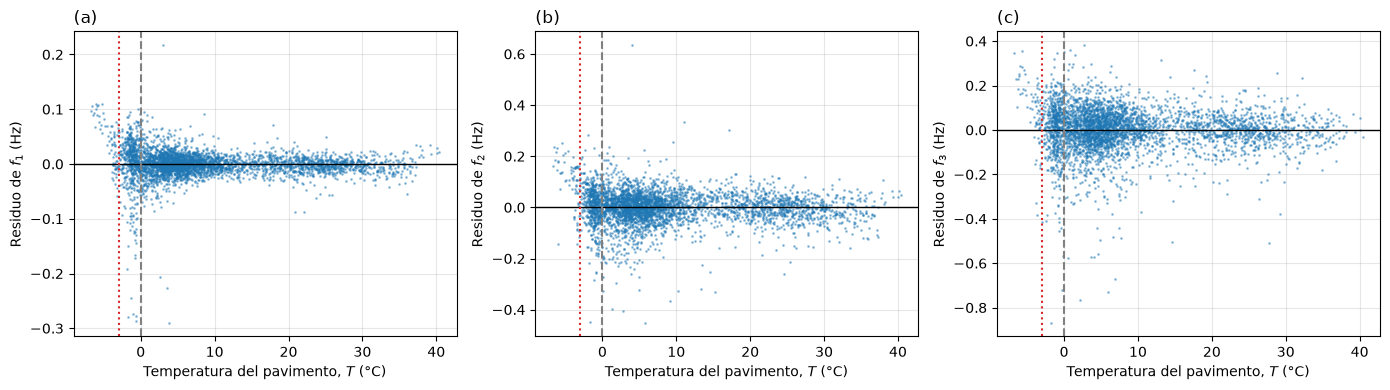

**Figura 12.** Residuos fuera del fold (Ec. 1) del mejor random forest de cada modo (Tabla 13) frente a la temperatura del pavimento: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua marca 0 °C y la punteada −3 °C.

In [29]:
# Out-of-fold residuals of the best forest of each mode (Table 13)
best_forest = {}
for mode in MODES:
    column = f"RMSE f{mode} (Hz)"
    best_forest[mode] = forest_table.loc[forest_table[column].idxmin()]
    predictions = cross_validate_forest(FLEXIBLE_FEATURES, mode, int(best_forest[mode]["Mínimo por hoja"]),
                                        int(best_forest[mode]["Variables por división"]))
    training[f"res_forest_f{mode}"] = training[f"f{mode}"] - predictions

    forest_rmse = rmse(training[f"res_forest_f{mode}"])
    cold_residual = training.loc[coldest, f"res_forest_f{mode}"].mean()
    print(f"f{mode}: best forest leaf {int(best_forest[mode]['Mínimo por hoja'])}, "
          f"features {int(best_forest[mode]['Variables por división'])}; RMSE {forest_rmse:.4f} Hz "
          f"(best network {rmse(training[f'res_mlp_f{mode}']):.4f} Hz); "
          f"below 0 °C {rmse(training.loc[below_zero, f'res_forest_f{mode}']):.4f} Hz; "
          f"mean residual below -3 °C {cold_residual:+.3f} Hz")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for i in range(3):
    mode = MODES[i]
    axes[i].plot(training["T"], training[f"res_forest_f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axhline(0, color="black", linewidth=1)
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].axvline(-3, color="tab:red", linestyle=":")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 12, "Residuos fuera del fold (Ec. 1) del mejor random forest de cada modo (Tabla 13) frente a la "
            "temperatura del pavimento: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua marca 0 °C y la "
            "punteada −3 °C.")

**Qué se ve:**

- **El random forest queda parecido a la red** (Tabla 13): su mejor combinación da 0.0268 Hz en $f_1$ (red: 0.0274 Hz), 0.0658 Hz en $f_2$ (red: 0.0657 Hz) y 0.1002 Hz en $f_3$ (red: 0.1025 Hz).
- **Es el mejor en $f_3$ bajo 0 °C:** 0.1323 Hz, frente a 0.1468 Hz de la red.
- **En $f_2$ sigue ganando la regresión lineal** (0.0622 Hz).
- **Con el frío intenso se queda corto:** el residuo medio bajo −3 °C es positivo (+0.037 Hz en $f_1$, +0.092 Hz en $f_2$, +0.086 Hz en $f_3$; Figura 12). Cada hoja predice una media de mediciones, así que no llega a los valores más altos de la frecuencia.
- **Hiperparámetros:** con una variable por división es el peor en todos los modos; con 5 o 7 es el mejor. Con 7, todas las variables compiten en cada pregunta, así que los árboles solo se diferencian por la muestra de mediciones. Con hojas de 50 mediciones empeora; con 5 a 20 da casi lo mismo.

Los tres tipos de modelo quedan cerca entre sí en $f_1$ y $f_3$, con diferencias de milésimas de Hz. Hace falta un criterio para elegir.

---
<a id="sec10"></a>
## 10. Elección del modelo de cada modo

### 10.1 Criterio: regla de un error estándar

El RMSE de un modelo cambia de un fold a otro, así que el modelo con el menor RMSE puede ganar solo por azar, según cómo cayeron los folds. La **regla de un error estándar** elige el modelo más simple cuyo RMSE no se distingue del mejor:

$$
\text{RMSE}_j \le \text{RMSE}_{\min} + \frac{s_{\min}}{\sqrt{k}}
\tag{10}
$$

donde $\text{RMSE}_j$ es el RMSE del modelo $j$, $\text{RMSE}_{\min}$ el menor RMSE de todos los modelos, $s_{\min}$ la desviación estándar del RMSE de ese mejor modelo entre los folds y $k = 5$ el número de folds. El lado derecho es el **umbral**; $s_{\min}/\sqrt{k}$ es el error estándar.

- **Candidatos de cada modo:** las 8 opciones de la regresión lineal (Tabla 10, pavimento), las 28 redes (Tabla 12) y los 20 random forest (Tabla 13).
- **Orden de simplicidad:** primero el tipo de modelo, en el orden en que se probaron (regresión lineal, red neuronal, random forest). Dentro de la regresión y de la red, el de menos parámetros (en la regresión, uno por variable más $\beta_0$; en la red, sus pesos y sesgos, Ec. 8). Dentro del random forest, el de hojas más grandes.
- Entre los candidatos bajo el umbral se toma el primero en ese orden; si hay empate, el de menor RMSE.

In [30]:
# 1. Number of parameters of a network: weights and biases of every layer (Eq. 8)
def count_mlp_parameters(n_inputs, hidden_layers):
    sizes = [n_inputs] + list(hidden_layers) + [1]    # inputs, hidden layers, output
    total = 0
    for i in range(len(sizes) - 1):
        total = total + sizes[i] * sizes[i + 1] + sizes[i + 1]
    return total


# 2. All the candidates. "Orden" is the model type and "Tamaño" orders the models of the same type
candidates = []
# 2a. Linear options (Table 10, pavement)
for option_label, windows in OPTIONS:
    table_row = linear_table[(linear_table["Temperatura"] == "Pavimento") & (linear_table["Variables"] == option_label)]
    n_parameters = len(linear_features("T", windows)) + 1
    candidate = {"Modelo": "Lineal, " + option_label, "Tipo": "Regresión lineal", "Orden": 1,
                 "Tamaño": n_parameters, "windows": windows, "Neuronas": "", "alpha": 0, "Hoja": 0, "Variables": 0}
    for mode in MODES:
        candidate[f"RMSE f{mode} (Hz)"] = table_row[f"RMSE f{mode} (Hz)"].iloc[0]
    candidates.append(candidate)
# 2b. Networks (Table 12)
for _, table_row in mlp_table.iterrows():
    layers_label = table_row["Neuronas por capa oculta"]
    n_parameters = count_mlp_parameters(len(FLEXIBLE_FEATURES), HIDDEN_LAYERS[layers_label])
    candidate = {"Modelo": f"Red {layers_label}, alpha = {table_row['alpha']:g}", "Tipo": "Red neuronal",
                 "Orden": 2, "Tamaño": n_parameters, "windows": [], "Neuronas": layers_label,
                 "alpha": table_row["alpha"], "Hoja": 0, "Variables": 0}
    for mode in MODES:
        candidate[f"RMSE f{mode} (Hz)"] = table_row[f"RMSE f{mode} (Hz)"]
    candidates.append(candidate)
# 2c. Random forests (Table 13): larger leaves = shorter trees = simpler
for _, table_row in forest_table.iterrows():
    leaf = int(table_row["Mínimo por hoja"])
    n_features = int(table_row["Variables por división"])
    candidate = {"Modelo": f"Random forest, hoja {leaf}, {n_features} variables", "Tipo": "Random forest",
                 "Orden": 3, "Tamaño": -leaf, "windows": [], "Neuronas": "", "alpha": 0, "Hoja": leaf,
                 "Variables": n_features}
    for mode in MODES:
        candidate[f"RMSE f{mode} (Hz)"] = table_row[f"RMSE f{mode} (Hz)"]
    candidates.append(candidate)
candidates = pd.DataFrame(candidates)


# 3. Out-of-fold predictions of one candidate
def predict_candidate(candidate, mode):
    if candidate["Tipo"] == "Regresión lineal":
        return cross_validate("Lineal", linear_features("T", candidate["windows"]), mode)
    elif candidate["Tipo"] == "Red neuronal":
        return cross_validate_mlp(FLEXIBLE_FEATURES, mode, HIDDEN_LAYERS[candidate["Neuronas"]], candidate["alpha"])
    else:
        return cross_validate_forest(FLEXIBLE_FEATURES, mode, int(candidate["Hoja"]), int(candidate["Variables"]))


# 4. One-standard-error rule (Eq. 10) in each mode
chosen_models = {}
thresholds = {}
rows = []
for mode in MODES:
    column = f"RMSE f{mode} (Hz)"

    # 4a. Best candidate and the standard deviation of its RMSE between folds
    best = candidates.loc[candidates[column].idxmin()]
    residuals = training[f"f{mode}"] - predict_candidate(best, mode)
    fold_errors = []
    for fold in range(1, N_FOLDS + 1):
        fold_errors.append(rmse(residuals[training["fold"] == fold]))
    s_min = np.std(fold_errors, ddof=1)
    threshold = best[column] + s_min / np.sqrt(N_FOLDS)

    # 4b. Simplest candidate under the threshold (model type, then size, then RMSE)
    under_threshold = candidates[candidates[column] <= threshold]
    under_threshold = under_threshold.sort_values(["Orden", "Tamaño", column])
    chosen = under_threshold.iloc[0]
    chosen_models[mode] = chosen
    thresholds[mode] = threshold

    rows.append({
        "Modo": mode,
        "Menor RMSE": best["Modelo"],
        "RMSE mín. (Hz)": best[column],
        "s mín. (Hz)": s_min,
        "Umbral (Hz)": threshold,
        "Candidatos bajo el umbral": len(under_threshold),
        "Elegido": chosen["Modelo"],
        "RMSE elegido (Hz)": chosen[column],
    })
show_table(pd.DataFrame(rows), 14, "Regla de un error estándar (Ec. 10) en cada modo: candidato con menor RMSE, "
           "desviación estándar de su RMSE entre folds, umbral, número de candidatos bajo el umbral y modelo "
           "elegido.", decimals=4)

**Tabla 14.** Regla de un error estándar (Ec. 10) en cada modo: candidato con menor RMSE, desviación estándar de su RMSE entre folds, umbral, número de candidatos bajo el umbral y modelo elegido.

Modo,Menor RMSE,RMSE mín. (Hz),s mín. (Hz),Umbral (Hz),Candidatos bajo el umbral,Elegido,RMSE elegido (Hz)
1,"Random forest, hoja 10, 7 variables",0.0268,0.0071,0.0299,26,"Red 30 y 30, alpha = 0.01",0.0291
2,"Lineal, + todas las ventanas",0.0622,0.0037,0.0638,2,"Lineal, + ventana de 168 h",0.0628
3,"Random forest, hoja 10, 7 variables",0.1002,0.0031,0.1016,4,"Random forest, hoja 20, 7 variables",0.1015


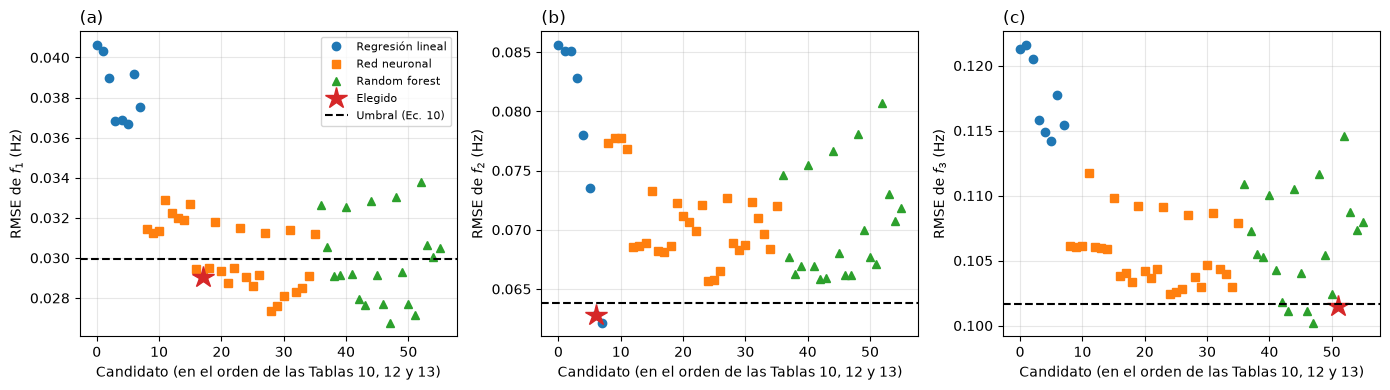

**Figura 13.** RMSE de validación (Ec. 2) de todos los candidatos con la temperatura del pavimento, umbral de la regla de un error estándar (Ec. 10) y modelo elegido (estrella roja): (a) $f_1$, (b) $f_2$, (c) $f_3$.

In [31]:
TYPE_STYLES = [("Regresión lineal", "o", "tab:blue"), ("Red neuronal", "s", "tab:orange"),
               ("Random forest", "^", "tab:green")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i in range(3):
    mode = MODES[i]
    column = f"RMSE f{mode} (Hz)"
    ax = axes[i]
    # One position per candidate: its row number in the candidates table
    for type_label, marker, color in TYPE_STYLES:
        type_rows = candidates[candidates["Tipo"] == type_label]
        ax.plot(type_rows.index, type_rows[column], marker, color=color, label=type_label)
    chosen = chosen_models[mode]
    ax.plot(chosen.name, chosen[column], "*", markersize=16, color="tab:red", label="Elegido")
    ax.axhline(thresholds[mode], color="black", linestyle="--", label="Umbral (Ec. 10)")
    ax.set_xlabel("Candidato (en el orden de las Tablas 10, 12 y 13)")
    ax.set_ylabel(f"RMSE de $f_{mode}$ (Hz)")
    ax.set_title(labels[i], loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)

fig.tight_layout()
show_figure(fig, 13, "RMSE de validación (Ec. 2) de todos los candidatos con la temperatura del pavimento, umbral "
            "de la regla de un error estándar (Ec. 10) y modelo elegido (estrella roja): (a) $f_1$, (b) $f_2$, "
            "(c) $f_3$.")

**Qué se ve** (Tabla 14, Figura 13):

- **$f_1$:** el menor RMSE es de un random forest (0.0268 Hz), pero cambia mucho entre folds ($s_{\min}$ = 0.0071 Hz) y el umbral queda en 0.0299 Hz. Bajo el umbral hay 26 candidatos, ninguno lineal. El más simple es la red de dos capas de 30 (`alpha` = 0.01, 0.0291 Hz).
- **$f_2$:** el menor RMSE es de la regresión lineal con todas las ventanas (0.0622 Hz). Bajo el umbral (0.0638 Hz) solo está también la regresión con la ventana de una semana (0.0628 Hz, 5 parámetros), y se elige esa. Ninguna red ni ningún random forest llega al umbral.
- **$f_3$:** el menor RMSE es de un random forest (0.1002 Hz) y el umbral queda en 0.1016 Hz. Bajo el umbral solo hay 4 random forest; ninguna red llega (la mejor, 0.1025 Hz). Se elige el de hojas más grandes (20 mediciones, 0.1015 Hz).

**Decisión:** el modelo de cada modo, con la temperatura del pavimento, es:

**Tabla 15.** Modelo elegido para cada modo.

| Modo | Modelo | Variables de entrada | Hiperparámetros | RMSE de validación (Hz) |
|---|---|---|---|---|
| $f_1$ | Red neuronal (Ec. 8) | $T$, $\bar{T}_6$, $\bar{T}_{12}$, $\bar{T}_{24}$, $\bar{T}_{48}$, $\bar{T}_{72}$, $\bar{T}_{168}$ | Dos capas de 30, `alpha` = 0.01 | 0.0291 |
| $f_2$ | Regresión lineal (Ec. 6) | $T$, $\min(T, 0)$, $\bar{T}_{168}$, $\min(\bar{T}_{168}, 0)$ | — | 0.0628 |
| $f_3$ | Random forest (Ec. 9) | $T$, $\bar{T}_6$, $\bar{T}_{12}$, $\bar{T}_{24}$, $\bar{T}_{48}$, $\bar{T}_{72}$, $\bar{T}_{168}$ | 200 árboles, mínimo 20 por hoja, 7 variables por división | 0.1015 |

---
<a id="sec11"></a>
## 11. Residuos en los bloques de prueba

Para el monitoreo, cada modelo de la Tabla 15 se ajusta con **todo el entrenamiento**, con los mismos hiperparámetros. Después predice la frecuencia de cada medición válida de los bloques de prueba (Tabla 3), y el residuo (Ec. 1) es la frecuencia medida menos la predicha.

- Las variables de entrada se calculan igual que en el entrenamiento: con la medición actual y las anteriores (Ec. 5).
- En el entrenamiento se usan los residuos fuera del fold del modelo elegido (paso 10). Así se comparan con residuos de mediciones que el modelo no vio, igual que en la prueba.

In [32]:
# 1. Variables of the linear model (Eq. 6) for all the measurements
data["T_below_zero"] = np.minimum(data["T"], 0)
for w in WINDOWS:
    data[f"T_mean_{w}h_below_zero"] = np.minimum(data[f"T_mean_{w}h"], 0)

# 2. Measurements to predict: the valid ones of the test blocks
test = data[data["valid"] & (data["block"] != "Entrenamiento")].copy()

# 3. f1: neural network with two layers of 30 and alpha = 0.01 (Table 15)
scaler = StandardScaler()
x_training = scaler.fit_transform(training[FLEXIBLE_FEATURES])
f1_mean = training["f1"].mean()
f1_std = training["f1"].std()
network = MLPRegressor(hidden_layer_sizes=(30, 30), alpha=0.01, early_stopping=True, max_iter=2000,
                       random_state=SEED)
network.fit(x_training, (training["f1"] - f1_mean) / f1_std)
test["predicted_f1"] = network.predict(scaler.transform(test[FLEXIBLE_FEATURES])) * f1_std + f1_mean

# 4. f2: linear regression with the one-week window (Table 15)
F2_FEATURES = linear_features("T", [168])
linear_model = LinearRegression()
linear_model.fit(training[F2_FEATURES], training["f2"])
test["predicted_f2"] = linear_model.predict(test[F2_FEATURES])

# 5. f3: random forest with leaves of at least 20 and 7 variables per split (Table 15)
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=7, random_state=SEED, n_jobs=-1)
forest.fit(training[FLEXIBLE_FEATURES], training["f3"])
test["predicted_f3"] = forest.predict(test[FLEXIBLE_FEATURES])

# 6. Residuals (Eq. 1): test blocks with the final models, training out of the fold (step 10)
for mode in MODES:
    test[f"residual_f{mode}"] = test[f"f{mode}"] - test[f"predicted_f{mode}"]
    training[f"residual_f{mode}"] = training[f"f{mode}"] - predict_candidate(chosen_models[mode], mode)

# 7. One table with the residuals of all the blocks, in time order
columns = ["start", "block", "T", "residual_f1", "residual_f2", "residual_f3"]
residuals_all = pd.concat([training[columns], test[columns]]).sort_values("start")

# 8. Mean and standard deviation of the residual of each mode in each block
rows = []
for block in BLOCK_USE:
    block_rows = residuals_all[residuals_all["block"] == block]
    if len(block_rows) == 0:
        continue                                  # the preparation has no valid measurements
    row = {"Bloque": block, "Mediciones": len(block_rows)}
    for mode in MODES:
        row[f"Media f{mode} (Hz)"] = block_rows[f"residual_f{mode}"].mean()
        row[f"Desv. est. f{mode} (Hz)"] = block_rows[f"residual_f{mode}"].std()
    rows.append(row)
show_table(pd.DataFrame(rows), 16, "Media y desviación estándar del residuo (Ec. 1) de cada modo en cada bloque. "
           "Entrenamiento: residuos fuera del fold; bloques de prueba: modelos ajustados con todo el entrenamiento.",
           decimals=4)

**Tabla 16.** Media y desviación estándar del residuo (Ec. 1) de cada modo en cada bloque. Entrenamiento: residuos fuera del fold; bloques de prueba: modelos ajustados con todo el entrenamiento.

Bloque,Mediciones,Media f1 (Hz),Desv. est. f1 (Hz),Media f2 (Hz),Desv. est. f2 (Hz),Media f3 (Hz),Desv. est. f3 (Hz)
Entrenamiento,3933,-0.0003,0.0291,0.0008,0.0628,0.0028,0.1015
"Prueba, puente sano (invierno)",320,0.0069,0.0198,0.0232,0.0437,0.0095,0.1068
"Prueba, puente sano (verano)",324,-0.0134,0.0390,-0.0626,0.0344,0.0186,0.0856
"Prueba, con daño",494,-0.0553,0.0403,-0.4101,0.1080,-0.1903,0.1180


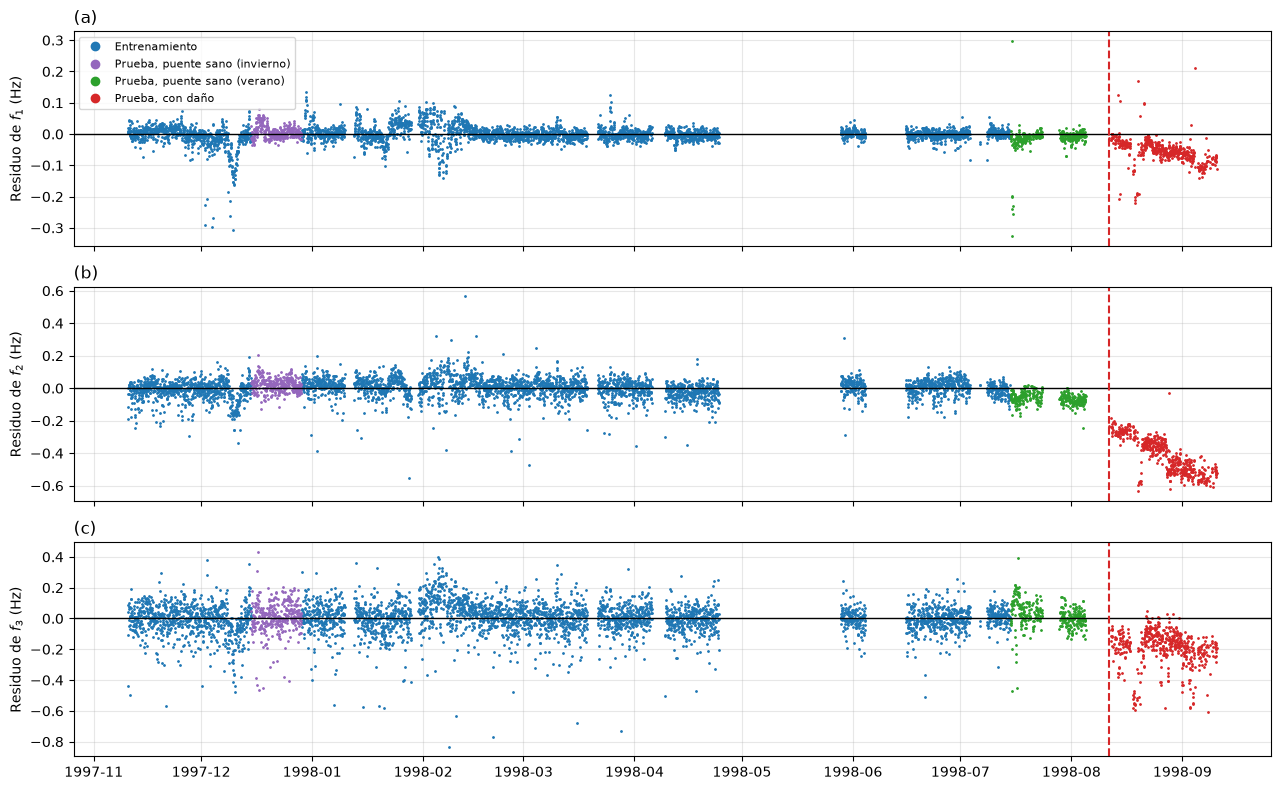

**Figura 14.** Residuos (Ec. 1) de los modelos elegidos (Tabla 15) del 10.11.1997 al 10.09.1998, por bloque: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua roja marca el primer descenso de la pila (11.08.1998, 13:15).

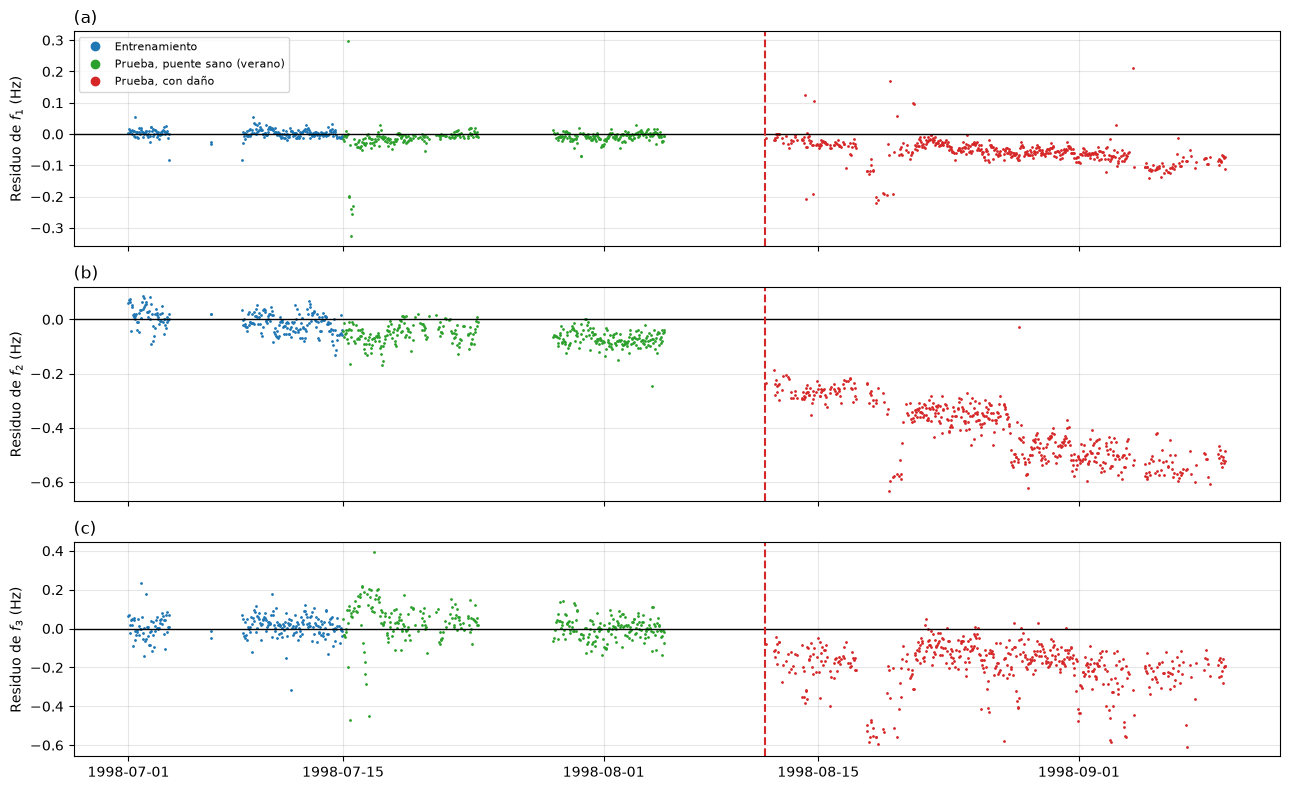

**Figura 15.** Residuos (Ec. 1) de los modelos elegidos (Tabla 15) del 01.07.1998 al 10.09.1998, por bloque: (a) $f_1$, (b) $f_2$, (c) $f_3$. La línea discontinua roja marca el primer descenso de la pila (11.08.1998, 13:15).

In [33]:
# Residuals in time: (1) whole monitoring, (2) from the summer test on
PERIODS = [(data["start"].min(), data["start"].max(), 14),
           (pd.Timestamp("1998-07-01"), data["start"].max(), 15)]

for period_start, period_end, figure_number in PERIODS:
    in_period = (residuals_all["start"] >= period_start) & (residuals_all["start"] <= period_end)
    period_rows = residuals_all[in_period]

    fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    for i in range(3):
        mode = MODES[i]
        for block in BLOCK_USE:
            block_rows = period_rows[period_rows["block"] == block]
            if len(block_rows) > 0:
                axes[i].plot(block_rows["start"], block_rows[f"residual_f{mode}"], ".", markersize=2,
                             color=COLORS[block], label=block)
        axes[i].axhline(0, color="black", linewidth=1)
        axes[i].axvline(DAMAGE_START, color="tab:red", linestyle="--")
        axes[i].set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
        axes[i].set_title(labels[i], loc="left")
        axes[i].grid(alpha=0.3)
    axes[0].legend(markerscale=6, fontsize=8, loc="upper left")

    fig.tight_layout()
    show_figure(fig, figure_number, f"Residuos (Ec. 1) de los modelos elegidos (Tabla 15) del "
                f"{period_start:%d.%m.%Y} al {period_end:%d.%m.%Y}, por bloque: (a) $f_1$, (b) $f_2$, (c) $f_3$. "
                "La línea discontinua roja marca el primer descenso de la pila (11.08.1998, 13:15).")

**Qué se ve:**

- **Puente sano, invierno** (Tabla 16, Figura 14): los residuos se parecen a los del entrenamiento. Las medias están cerca de 0 (de 0.007 a 0.023 Hz) y las desviaciones estándar son iguales o menores, salvo en $f_3$ (0.107 frente a 0.102 Hz).
- **Puente sano, verano** (Figura 15):
  - La dispersión es igual o menor que en el entrenamiento.
  - En $f_2$, los residuos quedan desplazados hacia abajo: media de −0.063 Hz, una desviación estándar del entrenamiento. Ya bajaban en los últimos días del entrenamiento (Figura 15b). Con estos datos no se identifica la causa.
  - El 15 y 16.07 hay unas pocas mediciones con residuos muy negativos en $f_1$ (hasta −0.33 Hz) y en $f_3$ (hasta −0.47 Hz), solo en algunas horas seguidas.
- **Puente con daño** (Figura 15):
  - **$f_2$ es el modo más sensible.** Su residuo baja de golpe a unos −0.25 Hz desde el primer descenso de la pila y después a −0.35 y −0.5 Hz, por escalones. En promedio, −0.410 Hz, unas 6.5 veces su desviación estándar del entrenamiento (0.063 Hz).
  - $f_3$ baja a entre −0.1 y −0.2 Hz, y $f_1$ baja poco a poco hasta unos −0.1 Hz. En promedio, los dos bajan unas 2 veces su desviación estándar del entrenamiento.
- **Ruido:**
  - Hay puntos aislados en todos los bloques, como los de la Figura 1.
  - En el entrenamiento hay episodios de varios días con residuos del mismo signo (por ejemplo, a principios de diciembre y en febrero), y aparecen en los tres modos a la vez.

**Decisión:** los modelos de la Tabla 15 se mantienen. Con el puente sano, los residuos de prueba tienen una dispersión parecida a la del entrenamiento, y con el daño se salen, sobre todo en $f_2$. Falta convertir los tres residuos de cada medición en una alarma.

---
<a id="sec12"></a>
## 12. Un indicador con los tres residuos

En un puente real no se sabe de antemano qué modo va a cambiar con el daño: depende de dónde y cómo ocurra. Por eso se usan los **tres residuos**, no uno solo.

Para juntarlos hay que saber cómo son con el puente sano: su escala y si se mueven juntos. Se mira en los residuos fuera del fold del entrenamiento.

In [34]:
# 1. Training residuals (out of the fold, step 11) of the three modes
RESIDUAL_COLUMNS = ["residual_f1", "residual_f2", "residual_f3"]
training_residuals = training[RESIDUAL_COLUMNS]

# 2. Standard deviation of each mode and correlation between modes
correlation = training_residuals.corr()
rows = []
for mode in MODES:
    column = f"residual_f{mode}"
    row = {"Modo": mode, "Desv. est. (Hz)": training_residuals[column].std()}
    for other_mode in MODES:
        row[f"Correlación con f{other_mode}"] = correlation.loc[column, f"residual_f{other_mode}"]
    rows.append(row)
show_table(pd.DataFrame(rows), 17, "Desviación estándar del residuo (Ec. 1) de cada modo y correlación entre los "
           "residuos de los tres modos, en el entrenamiento (fuera del fold).", decimals=3)

**Tabla 17.** Desviación estándar del residuo (Ec. 1) de cada modo y correlación entre los residuos de los tres modos, en el entrenamiento (fuera del fold).

Modo,Desv. est. (Hz),Correlación con f1,Correlación con f2,Correlación con f3
1,0.029,1.000,0.263,0.194
2,0.063,0.263,1.000,0.192
3,0.102,0.194,0.192,1.000


- **Escalas distintas:** la desviación estándar de $f_3$ es unas 3.5 veces la de $f_1$ (Tabla 17). Si se sumaran los residuos tal cual, $f_3$ dominaría el indicador.
- **Se mueven algo juntos:** la correlación entre modos es positiva, de 0.19 a 0.26 (Tabla 17). Es baja, pero no nula: los episodios de varios días del paso 11 aparecen en los tres modos. Si se trataran como independientes, esos episodios pesarían de más.

La **distancia de Mahalanobis** resuelve las dos cosas. Mide qué tan lejos está el vector de residuos de una medición del comportamiento del puente sano, en unidades de su variación y descontando lo que los modos tienen en común:

$$
D_i^2 = \left(\mathbf{r}_i - \bar{\mathbf{r}}\right)^\top \mathbf{S}^{-1} \left(\mathbf{r}_i - \bar{\mathbf{r}}\right)
\tag{11}
$$

donde $\mathbf{r}_i = (r_{1,i}, r_{2,i}, r_{3,i})$ es el vector con los residuos de los tres modos en la medición $i$ (Ec. 1), $\bar{\mathbf{r}}$ su media en el entrenamiento y $\mathbf{S}$ su matriz de covarianza en el entrenamiento.

- Si los residuos no estuvieran correlacionados, $D_i^2$ sería la suma de los tres residuos al cuadrado, cada uno dividido por su varianza.
- $\bar{\mathbf{r}}$ y $\mathbf{S}$ se calculan solo con el entrenamiento. Si los residuos fueran normales, $D^2$ del puente sano tendría media 3 (uno por modo).
- Cualquier cambio grande en uno o en varios modos aumenta $D^2$.

In [35]:
# 1. Mean vector and covariance matrix of the training residuals (Eq. 11)
residual_mean = training_residuals.mean().to_numpy()
covariance = np.cov(training_residuals.to_numpy(), rowvar=False)
inverse_covariance = np.linalg.inv(covariance)


# 2. Squared Mahalanobis distance of every measurement (Eq. 11)
def mahalanobis_squared(residual_table):
    distances = []
    for _, row in residual_table.iterrows():
        difference = row[RESIDUAL_COLUMNS].to_numpy(dtype=float) - residual_mean
        distances.append(difference @ inverse_covariance @ difference)    # @ is the matrix product
    return distances


residuals_all["D2"] = mahalanobis_squared(residuals_all)

# 3. Summary of D2 in each block
rows = []
for block in BLOCK_USE:
    block_rows = residuals_all[residuals_all["block"] == block]
    if len(block_rows) == 0:
        continue                                  # the preparation has no valid measurements
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_rows),
        "Media de D²": block_rows["D2"].mean(),
        "Mediana de D²": block_rows["D2"].median(),
        "D² máximo": block_rows["D2"].max(),
    })
show_table(pd.DataFrame(rows), 18, "Distancia de Mahalanobis al cuadrado (Ec. 11) en cada bloque.", decimals=2)

**Tabla 18.** Distancia de Mahalanobis al cuadrado (Ec. 11) en cada bloque.

Bloque,Mediciones,Media de D²,Mediana de D²,D² máximo
Entrenamiento,3933,3.00,1.24,118.14
"Prueba, puente sano (invierno)",320,2.26,1.16,35.62
"Prueba, puente sano (verano)",324,4.36,1.93,136.43
"Prueba, con daño",494,49.36,49.01,180.32


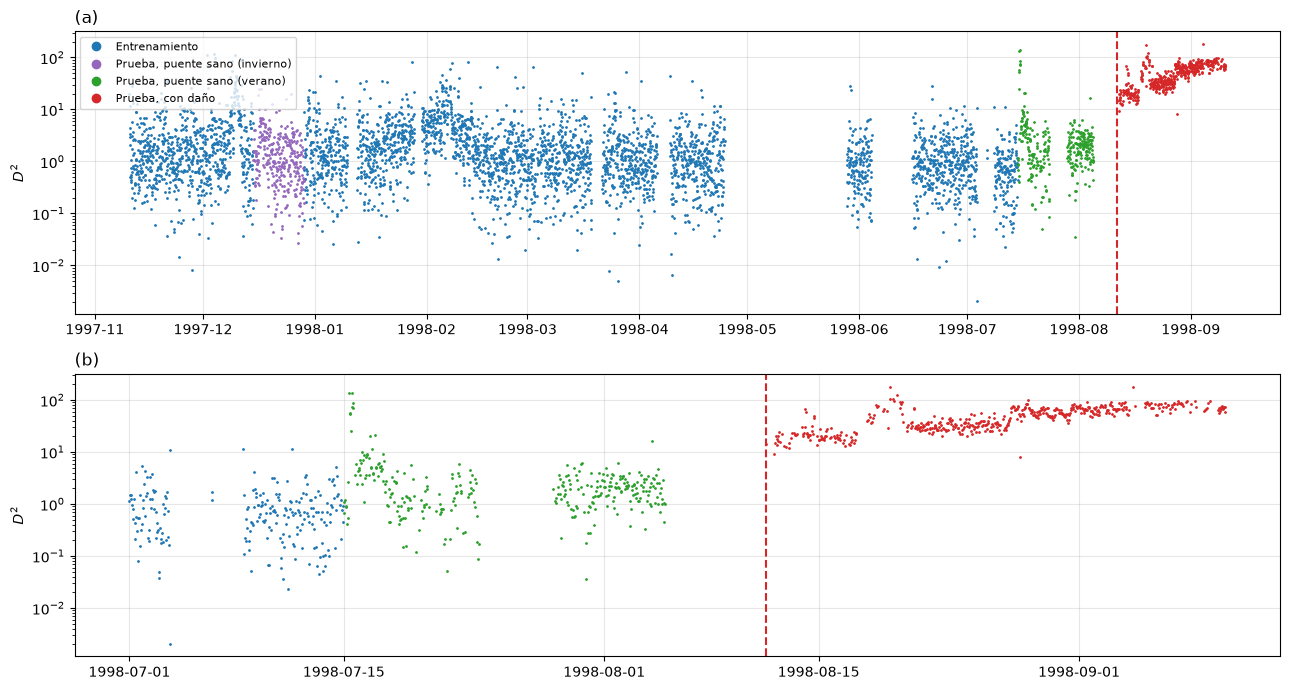

**Figura 16.** Distancia de Mahalanobis al cuadrado (Ec. 11, escala logarítmica) por bloque: (a) todo el monitoreo y (b) desde el 01.07.1998. La línea discontinua roja marca el primer descenso de la pila.

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
PANELS = [(data["start"].min(), "(a)"), (pd.Timestamp("1998-07-01"), "(b)")]
for i in range(2):
    period_start, panel_label = PANELS[i]
    period_rows = residuals_all[residuals_all["start"] >= period_start]
    for block in BLOCK_USE:
        block_rows = period_rows[period_rows["block"] == block]
        if len(block_rows) > 0:
            axes[i].plot(block_rows["start"], block_rows["D2"], ".", markersize=2, color=COLORS[block], label=block)
    axes[i].axvline(DAMAGE_START, color="tab:red", linestyle="--")
    axes[i].set_yscale("log")
    axes[i].set_ylabel("$D^2$")
    axes[i].set_title(panel_label, loc="left")
    axes[i].grid(alpha=0.3)
axes[0].legend(markerscale=6, fontsize=8, loc="upper left")

fig.tight_layout()
show_figure(fig, 16, "Distancia de Mahalanobis al cuadrado (Ec. 11, escala logarítmica) por bloque: (a) todo el "
            "monitoreo y (b) desde el 01.07.1998. La línea discontinua roja marca el primer descenso de la pila.")

**Qué se ve:**

- **Entrenamiento** (Tabla 18): la media de $D^2$ es 3.00, pero la mediana es 1.24. Casi todas las mediciones tienen $D^2$ pequeño y unas pocas muy grande (hasta 118). Además hay episodios de varios días con $D^2$ entre 10 y 30, como a principios de febrero (Figura 16a).
- **Puente sano, invierno:** igual que el entrenamiento (mediana 1.16, máximo 35.6).
- **Puente sano, verano:**
  - La mediana es mayor (1.93), por el desplazamiento de $f_2$ del paso 11.
  - Las horas del 15 y 16.07 llegan a $D^2$ = 136, más que el máximo del entrenamiento (Figura 16b).
- **Puente con daño:** la mediana es 49, unas 40 veces la del entrenamiento, y $D^2$ sube por escalones. Pero en los primeros días después del descenso de la pila, $D^2$ está entre 10 y 30 (Figura 16b), por debajo de las horas aisladas del puente sano.
- **Consecuencia:**
  - Un límite sobre cada hora tendría que estar por encima de 136 para no dar alarma el 15 y 16.07. Con ese límite, los primeros días del daño no darían alarma.
  - Hay una diferencia útil: las horas altas del puente sano son pocas y aisladas, mientras que el daño se mantiene en el tiempo.

**Decisión:** el indicador es la distancia de Mahalanobis al cuadrado, $D^2$ (Ec. 11). Falta tratar el ruido de las horas aisladas.